# Customer Churn Prediction & Data Quality Pipeline
**UST Python AI/ML Beginner Capstone · IBM Telco Customer Churn**（電信客戶流失預測）

> **Mission** — build a small, reproducible Python ML application that loads customer data, validates and cleans it, explores patterns, trains a classifier, evaluates the predictions, writes a customer-risk output and runs its tests automatically in GitHub Actions.

**How this notebook works ｜ 這本 notebook 的用法**

The brief asks for a *modular Python project*, not "a notebook full of disconnected code". So this notebook is the **guided build and demo** of that project:

1. every `%%writefile` cell writes a real file of the repository (`src/…`, `tests/…`, `main.py`, `.github/workflows/ci.yml`, `README.md`);
2. the cells right after it import that module and run it on the real data, so each step is checked as soon as it is written;
3. in Session 3 the same code runs as a command-line app (`python main.py`) and as a test suite (`pytest`).

Open the notebook in the folder that should become the repository root and use **Run All** (or *Restart Kernel and Run All*). Re-running is safe: files are rewritten with the same content, the raw CSV is downloaded only when it is missing, and it is never modified.

> To change a module, edit its `%%writefile` cell and re-run it — otherwise the next Run All overwrites your edit with the cell's version.

| Section | Brief | What gets built |
|---|---|---|
| 0 · Setup | – | environment check |
| 1 · Session 1 — Tasks 1–5 | data understanding, validation, cleaning, EDA | `src/config.py`, `data_loader.py`, `validator.py`, `preprocessing.py`, `analysis.py`, `charts.py` |
| 2 · Session 2 — Tasks 6–10 | ML pipeline (+ optional second model) | `src/model.py`, `evaluation.py`, `output/predictions.csv` |
| 3 · Session 3 — Tasks 11–14 | refactor, tests, CI, README | `src/pipeline.py`, `main.py`, `tests/`, `.github/workflows/ci.yml`, `README.md` |
| 4 · Submission check & demo prep | sections 14, 19, 23 | checklist, demo plan, Q&A answers |

## 0 · Setup ｜ 環境設定

Needs Python 3.9+ with pandas, NumPy, scikit-learn, Matplotlib and pytest. In a fresh environment (terminal, in this folder):

```bash
python -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate
pip install pandas numpy scikit-learn matplotlib pytest notebook
```

The cell below checks the packages, puts this folder on the import path (so `import src` works) and turns on `autoreload`, which re-imports a module automatically after its `%%writefile` cell is re-run.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

PROJECT_ROOT = Path.cwd()  # the notebook's folder = the repository root
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Python       {sys.version.split()[0]}")
missing = []
for package in ["pandas", "numpy", "scikit-learn", "matplotlib", "pytest"]:
    try:
        print(f"{package:<12} {version(package)}")
    except PackageNotFoundError:
        missing.append(package)
if missing:
    raise ImportError(f"Missing packages: {missing}. Install them with: pip install {' '.join(missing)}")
print(f"Project root: ./{PROJECT_ROOT.name}")

Python       3.11.16
pandas       2.3.1
numpy        2.3.1
scikit-learn 1.8.0
matplotlib   3.10.3
pytest       8.4.1
Project root: ./telco-churn-capstone


# 1 · Session 1 — Data understanding, validation & analysis
**Goal:** turn the raw CSV into a trustworthy, documented dataset that is ready for ML.（把原始 CSV 變成可信、可建模的資料）

## Task 1 — Create the project ｜ 建立專案結構

The layout follows the brief: `data/raw/` holds the original file (only ever read), `data/processed/` the cleaned copy, `src/` the package, `tests/` the pytest suite and `output/` everything the program produces.

```
telco-churn-capstone/
├── data/raw/   data/processed/
├── src/        tests/
├── output/figures/   .github/workflows/
├── main.py   requirements.txt   README.md   .gitignore   pytest.ini
└── telco_churn_capstone.ipynb   ← this notebook
```

In [2]:
FOLDERS = ["data/raw", "data/processed", "src", "tests", "output/figures", ".github/workflows"]
for folder in FOLDERS:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
print("Folders ready:", ", ".join(FOLDERS))

Folders ready: data/raw, data/processed, src, tests, output/figures, .github/workflows


**`requirements.txt`** — the four core libraries from the brief plus Matplotlib (used for the charts). Only lower bounds, no exact pins (the brief asks for pins only if the instructor requires them).

In [3]:
%%writefile requirements.txt
pandas>=1.5
numpy>=1.23
scikit-learn>=1.2
matplotlib>=3.6
pytest>=7.0

Writing requirements.txt


**`.gitignore`** — keeps caches, virtual environments and regenerated data out of Git. The small files in `output/` stay tracked as example output, because the brief lists `output/predictions.csv` as a deliverable.

In [4]:
%%writefile .gitignore
# Python caches and virtual environments
__pycache__/
*.py[cod]
.venv/
venv/
.pytest_cache/
.ipynb_checkpoints/

# OS / editor files
.DS_Store
.vscode/
.idea/

# Regenerated by the pipeline (the small files in output/ are kept as example output)
data/processed/

Writing .gitignore


**`pytest.ini`** — lets a plain `pytest` from the repository root find the tests *and* import `src` (the brief's troubleshooting row "pytest cannot find module").

In [5]:
%%writefile pytest.ini
[pytest]
# Run from the repository root: tests live in tests/, and the root goes on the
# import path so `import src` works locally and in GitHub Actions.
testpaths = tests
pythonpath = .

Writing pytest.ini


**`src/__init__.py`** makes `src` a package. **`src/config.py`** keeps every setting in one place: paths (built from the project folder, so nothing is machine-specific), the column groups from the data dictionary, the allowed values the validator checks against, and the model settings (`test_size`, `random_state`, hyper-parameters). The other modules import these names instead of repeating them — it is also the small configuration file from the bonus list.

In [6]:
%%writefile src/__init__.py
"""Telco customer churn capstone: validation, cleaning, analysis and ML pipeline."""

Writing src/__init__.py


In [7]:
%%writefile src/config.py
"""Project settings in one place: paths, column groups, validation rules and model settings.

Every other module imports these values, so a column list or a number such as
the test size is never repeated - an experiment is changed here, in one spot.
"""
from pathlib import Path

# --- Paths: relative to the project folder, so the code runs on any machine ---
PROJECT_ROOT = Path(__file__).resolve().parent.parent
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco-Customer-Churn.csv"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "telco_churn_clean.csv"
OUTPUT_DIR = PROJECT_ROOT / "output"
DATASET_URL = (
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

# --- Columns ---
ID_COLUMN = "customerID"  # identifies a customer; kept for the output, never a feature
TARGET_COLUMN = "Churn"  # "Yes"/"No" in the raw file, 1/0 after cleaning
NUMERIC_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges"]
BINARY_FEATURES = ["SeniorCitizen"]  # already stored as 0/1
CATEGORICAL_FEATURES = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod",
]
FEATURE_COLUMNS = NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES
REQUIRED_COLUMNS = [ID_COLUMN] + FEATURE_COLUMNS + [TARGET_COLUMN]

# --- Validation rules, taken from the data dictionary ---
TARGET_LABELS = {"Yes", "No"}
TARGET_MAPPING = {"No": 0, "Yes": 1}
YES_NO = {"Yes", "No"}
INTERNET_ADDON = {"Yes", "No", "No internet service"}
INTERNET_ADDON_COLUMNS = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
ALLOWED_VALUES = {
    "gender": {"Male", "Female"},
    "SeniorCitizen": {0, 1},
    "Partner": YES_NO,
    "Dependents": YES_NO,
    "PhoneService": YES_NO,
    "MultipleLines": {"Yes", "No", "No phone service"},
    "InternetService": {"DSL", "Fiber optic", "No"},
    "OnlineSecurity": INTERNET_ADDON,
    "OnlineBackup": INTERNET_ADDON,
    "DeviceProtection": INTERNET_ADDON,
    "TechSupport": INTERNET_ADDON,
    "StreamingTV": INTERNET_ADDON,
    "StreamingMovies": INTERNET_ADDON,
    "Contract": {"Month-to-month", "One year", "Two year"},
    "PaperlessBilling": YES_NO,
    "PaymentMethod": {
        "Electronic check", "Mailed check",
        "Bank transfer (automatic)", "Credit card (automatic)",
    },
}
TENURE_RANGE = (0, 120)  # months; a generous sanity bound (10 years)
NON_NEGATIVE_COLUMNS = ["MonthlyCharges", "TotalCharges"]

# --- Model settings ---
TEST_SIZE = 0.20
RANDOM_STATE = 42
PRIMARY_MODEL = "logistic_regression"
LOGISTIC_REGRESSION_PARAMS = {"max_iter": 1000}
DECISION_TREE_PARAMS = {"max_depth": 5, "min_samples_leaf": 20}

# --- Risk bands for the predictions file (simple cut-offs to prioritise outreach) ---
RISK_BINS = [0.0, 0.3, 0.6, 1.0]
RISK_LABELS = ["Low", "Medium", "High"]

Writing src/config.py


## Task 2 — Load and inspect the data ｜ 載入與檢視資料

`src/data_loader.py`:
* `load_raw_data(path)` takes the path as an argument (configurable — `main.py` exposes it as `--input`), checks that the file exists and is a non-empty CSV, and returns the data **exactly as stored**: no type conversion yet, so the validator sees the raw values.
* `download_dataset()` fetches the IBM CSV only when it is missing. It never overwrites an existing file, so an instructor-provided copy always wins.
* `summarize_dataset()` gives one row per column: dtype, filled cells, NaN cells and distinct values.

In [8]:
%%writefile src/data_loader.py
"""Load the raw Telco CSV and run basic input checks."""
from __future__ import annotations

import urllib.request
from pathlib import Path

import pandas as pd

from src import config


def download_dataset(destination: str | Path = config.RAW_DATA_PATH, url: str = config.DATASET_URL) -> Path:
    """Download the IBM CSV to `destination` unless the file is already there.

    An existing file is never overwritten, so an instructor-provided copy wins.
    """
    destination = Path(destination)
    if destination.exists():
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    partial = destination.with_name(destination.name + ".part")
    urllib.request.urlretrieve(url, partial)
    partial.replace(destination)  # only a complete download gets the real name
    return destination


def load_raw_data(path: str | Path) -> pd.DataFrame:
    """Read the CSV exactly as stored on disk.

    No type conversion happens here on purpose: the validator has to see the
    raw values (for example, TotalCharges arrives as text).
    """
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f"Input file not found: {path}. Put Telco-Customer-Churn.csv in "
            "data/raw/ (see README) or pass another file with --input."
        )
    if path.suffix.lower() != ".csv":
        raise ValueError(f"Expected a .csv file, got: {path.name}")
    df = pd.read_csv(path)
    if df.empty:
        raise ValueError(f"The input file has no data rows: {path}")
    return df


def summarize_dataset(df: pd.DataFrame) -> pd.DataFrame:
    """One row per column: data type, filled cells, NaN cells and distinct values."""
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "missing_nan": df.isna().sum(),
        "unique_values": df.nunique(),
    })

Writing src/data_loader.py


In [9]:
import hashlib

import pandas as pd

from src import config
from src.data_loader import download_dataset, load_raw_data, summarize_dataset

RAW_CSV = config.RAW_DATA_PATH  # data/raw/Telco-Customer-Churn.csv
download_dataset(RAW_CSV)       # does nothing when the file is already there
raw_fingerprint = hashlib.sha256(RAW_CSV.read_bytes()).hexdigest()  # used later to prove the file is unchanged

raw_df = load_raw_data(RAW_CSV)
print("Shape (rows, columns):", raw_df.shape)
raw_df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [11]:
summarize_dataset(raw_df)

,dtype,non_null,missing_nan,unique_values
customerID,object,7043,0,7043
gender,object,7043,0,2
SeniorCitizen,int64,7043,0,2
Partner,object,7043,0,2
Dependents,object,7043,0,2
tenure,int64,7043,0,73
PhoneService,object,7043,0,2
MultipleLines,object,7043,0,3
InternetService,object,7043,0,3
OnlineSecurity,object,7043,0,3


**What the inspection shows**
* 7,043 rows × 21 columns, as the brief says.
* `isna()` reports **no missing values at all** …
* … yet `TotalCharges` has a text dtype (`object`; `str` in pandas 3) although it holds money amounts. A numeric column that pandas could not read as numbers is a red flag — Task 3 finds out why.
* `SeniorCitizen` is already 0/1, while the other yes/no style columns are text that will need encoding.

## Task 3 — Build a validation report ｜ 資料驗證報告

`src/validator.py` answers each question from the brief with a small function that can be tested on its own; `validate_raw_data()` collects the answers in a `ValidationReport` dataclass that prints in plain English.

| Brief question | Function |
|---|---|
| rows / columns, data types | `ValidationReport` counts, `numeric_columns_stored_as_text()` |
| are the required columns there? | `find_missing_columns()` |
| duplicated customer IDs? | `find_duplicate_ids()` |
| which columns have missing values? | `count_missing_values()` — NaN **and** blank text |
| does TotalCharges behave like a number? | `find_non_numeric_values()` |
| tenure in a reasonable range? | `count_out_of_range()` with 0–120 months |
| charges non-negative? | `count_negative_values()` |
| Churn only Yes/No? | `find_invalid_values()` |
| unexpected categories? | `find_unexpected_categories()` against the data dictionary |
| business rule | `count_service_inconsistencies()`: no internet ⇒ every add-on says "No internet service"; no phone ⇒ "No phone service" |

The overall status is **PASS** when nothing needs fixing, otherwise **REVIEW** with the list of items to handle.

In [12]:
%%writefile src/validator.py
"""Data-quality checks for the raw Telco churn data.

Each check is a small function that returns plain Python data, so it can be
tested on its own. `validate_raw_data` runs them all and collects the answers
in a `ValidationReport`, which prints as a plain-English summary.
"""
from __future__ import annotations

from dataclasses import dataclass, field
from pathlib import Path

import pandas as pd

from src import config

SERVICE_COLUMNS = ["PhoneService", "MultipleLines", "InternetService"] + config.INTERNET_ADDON_COLUMNS


# ---------------------------------------------------------------- single checks
def find_missing_columns(df: pd.DataFrame, required: list[str] = config.REQUIRED_COLUMNS) -> list[str]:
    """Required columns that are not in the data."""
    return [column for column in required if column not in df.columns]


def find_duplicate_ids(df: pd.DataFrame, id_column: str = config.ID_COLUMN) -> list[str]:
    """Customer IDs that appear more than once (each listed once, sorted)."""
    is_duplicate = df[id_column].duplicated(keep=False)
    return sorted(set(df.loc[is_duplicate, id_column].astype(str)))


def count_missing_values(df: pd.DataFrame) -> dict[str, int]:
    """Missing values per column: real NaN cells plus blank or whitespace-only text.

    pandas turns an empty cell into NaN, but a cell holding a single space is
    read as the text " " - it looks filled in, yet carries no value.
    """
    counts = {}
    for column in df.columns:
        values = df[column]
        missing = int(values.isna().sum())
        if not pd.api.types.is_numeric_dtype(values):
            missing += int((values.dropna().astype(str).str.strip() == "").sum())
        if missing:
            counts[column] = missing
    return counts


def find_non_numeric_values(series: pd.Series) -> pd.Series:
    """Values that cannot be converted to a number (NaN cells are not included)."""
    as_number = pd.to_numeric(series, errors="coerce")
    return series[as_number.isna() & series.notna()]


def numeric_columns_stored_as_text(df: pd.DataFrame, columns: list[str] = config.NUMERIC_FEATURES) -> list[str]:
    """Numeric columns that pandas could not read as numbers."""
    return [
        column for column in columns
        if column in df.columns and not pd.api.types.is_numeric_dtype(df[column])
    ]


def count_negative_values(df: pd.DataFrame, columns: list[str] = config.NON_NEGATIVE_COLUMNS) -> dict[str, int]:
    """Values below zero per column (text is converted to numbers first)."""
    counts = {}
    for column in columns:
        if column in df.columns:
            negative = int((pd.to_numeric(df[column], errors="coerce") < 0).sum())
            if negative:
                counts[column] = negative
    return counts


def count_out_of_range(series: pd.Series, low: float, high: float) -> int:
    """Number of values outside the closed range [low, high]."""
    values = pd.to_numeric(series, errors="coerce")
    return int(((values < low) | (values > high)).sum())


def find_invalid_values(series: pd.Series, allowed: set) -> dict:
    """{unexpected value: count} for values not in `allowed` (NaN is ignored)."""
    counts = series.dropna().value_counts()
    return {_plain(value): int(n) for value, n in counts.items() if value not in allowed}


def find_unexpected_categories(df: pd.DataFrame, allowed_values: dict = config.ALLOWED_VALUES) -> dict[str, dict]:
    """Columns holding values outside the data dictionary, with those values."""
    problems = {}
    for column, allowed in allowed_values.items():
        if column in df.columns:
            invalid = find_invalid_values(df[column], allowed)
            if invalid:
                problems[column] = invalid
    return problems


def count_service_inconsistencies(df: pd.DataFrame) -> int:
    """Rows that break the service business rules.

    No internet service <-> every internet add-on says "No internet service".
    No phone service    <-> MultipleLines says "No phone service".
    """
    no_internet = df["InternetService"] == "No"
    addon_says_no_internet = df[config.INTERNET_ADDON_COLUMNS] == "No internet service"
    internet_mismatch = addon_says_no_internet.ne(no_internet, axis=0).any(axis=1)
    phone_mismatch = (df["MultipleLines"] == "No phone service") != (df["PhoneService"] == "No")
    return int((internet_mismatch | phone_mismatch).sum())


def _plain(value):
    """NumPy scalars (e.g. np.int64) -> plain Python values, for readable output."""
    return value.item() if hasattr(value, "item") else value


def _format_counts(counts: dict) -> str:
    return ", ".join(f"{key} ({value})" for key, value in counts.items())


# ---------------------------------------------------------------- the report
@dataclass
class ValidationReport:
    """Answers to the validation questions, with helpers to judge and print them."""

    n_rows: int
    n_columns: int
    dtypes: dict[str, str]
    missing_columns: list[str] = field(default_factory=list)
    text_numeric_columns: list[str] = field(default_factory=list)
    duplicate_ids: list[str] = field(default_factory=list)
    missing_values: dict[str, int] = field(default_factory=dict)
    target_counts: dict = field(default_factory=dict)
    invalid_target_values: dict = field(default_factory=dict)
    total_charges_issues: int = 0
    total_charges_issue_tenures: list = field(default_factory=list)
    negative_values: dict[str, int] = field(default_factory=dict)
    out_of_range_tenure: int = 0
    unexpected_categories: dict[str, dict] = field(default_factory=dict)
    service_inconsistencies: int = 0

    @property
    def issues(self) -> list[str]:
        """Every problem found, in plain English (empty list = nothing to fix)."""
        low, high = config.TENURE_RANGE
        checks = [
            (self.missing_columns, f"Required columns missing: {', '.join(self.missing_columns)}"),
            (self.duplicate_ids, f"{len(self.duplicate_ids)} customer ID(s) appear more than once"),
            (self.missing_values, f"Missing or blank values in: {_format_counts(self.missing_values)}"),
            (self.invalid_target_values, f"Churn labels other than Yes/No: {self.invalid_target_values}"),
            (self.total_charges_issues,
             f"TotalCharges has {self.total_charges_issues} value(s) that are not numbers"),
            (self.negative_values, f"Negative values in: {_format_counts(self.negative_values)}"),
            (self.out_of_range_tenure, f"{self.out_of_range_tenure} tenure value(s) outside {low}-{high} months"),
            (self.unexpected_categories, f"Unexpected category values: {self.unexpected_categories}"),
            (self.service_inconsistencies,
             f"{self.service_inconsistencies} row(s) break the phone/internet service rules"),
        ]
        return [message for found, message in checks if found]

    @property
    def status(self) -> str:
        return "PASS" if not self.issues else "REVIEW"

    def to_text(self) -> str:
        """The report as plain text that a non-programmer can follow."""
        low, high = config.TENURE_RANGE
        type_counts = pd.Series(self.dtypes).value_counts().to_dict()
        total_charges = "none"
        if self.total_charges_issues:
            tenures = ", ".join(str(tenure) for tenure in self.total_charges_issue_tenures)
            total_charges = (f"{self.total_charges_issues} blank/non-numeric value(s); "
                             f"tenure of those customers: {tenures}")
        lines = [
            "DATA VALIDATION REPORT",
            "----------------------",
            f"Rows: {self.n_rows}",
            f"Columns: {self.n_columns}",
            f"Required columns missing: {', '.join(self.missing_columns) or 'none'}",
            f"Column types: {_format_counts(type_counts)}",
            f"Numeric columns stored as text: {', '.join(self.text_numeric_columns) or 'none'}",
            f"Duplicate customer IDs: {len(self.duplicate_ids)}",
            f"Missing-value fields: {_format_counts(self.missing_values) or 'none'}",
            f"Target labels (Churn): {_format_counts(self.target_counts) or 'n/a'}",
            f"Invalid target values: {self.invalid_target_values or 'none'}",
            f"TotalCharges conversion issues: {total_charges}",
            f"Negative numeric values: {_format_counts(self.negative_values) or 'none'}",
            f"Tenure outside {low}-{high} months: {self.out_of_range_tenure}",
            f"Unexpected categorical values: {self.unexpected_categories or 'none'}",
            f"Service consistency issues: {self.service_inconsistencies}",
            f"Overall status: {self.status}",
        ]
        if self.issues:
            lines.append("To handle before modelling:")
            lines += [f"  - {issue}" for issue in self.issues]
        return "\n".join(lines)


# ---------------------------------------------------------------- run everything
def validate_raw_data(df: pd.DataFrame) -> ValidationReport:
    """Run every check on the raw data. The DataFrame is only read, never changed."""
    columns = set(df.columns)
    report = ValidationReport(
        n_rows=len(df),
        n_columns=df.shape[1],
        dtypes=df.dtypes.astype(str).to_dict(),
        missing_columns=find_missing_columns(df),
        text_numeric_columns=numeric_columns_stored_as_text(df),
        missing_values=count_missing_values(df),
        negative_values=count_negative_values(df),
        unexpected_categories=find_unexpected_categories(df),
    )
    if config.ID_COLUMN in columns:
        report.duplicate_ids = find_duplicate_ids(df)
    if config.TARGET_COLUMN in columns:
        target = df[config.TARGET_COLUMN]
        report.target_counts = {_plain(label): int(n) for label, n in target.value_counts().items()}
        report.invalid_target_values = find_invalid_values(target, config.TARGET_LABELS)
    if "TotalCharges" in columns:
        not_numeric = find_non_numeric_values(df["TotalCharges"])
        report.total_charges_issues = len(not_numeric)
        if "tenure" in columns:
            report.total_charges_issue_tenures = sorted(set(df.loc[not_numeric.index, "tenure"].tolist()))
    if "tenure" in columns:
        report.out_of_range_tenure = count_out_of_range(df["tenure"], *config.TENURE_RANGE)
    if set(SERVICE_COLUMNS) <= columns:
        report.service_inconsistencies = count_service_inconsistencies(df)
    return report


def check_clean_data(df: pd.DataFrame) -> list[str]:
    """Rules the cleaned table must meet before modelling (empty list = PASS)."""
    problems = []
    missing = count_missing_values(df)
    if missing:
        problems.append(f"missing values remain: {missing}")
    not_numeric = numeric_columns_stored_as_text(df)
    if not_numeric:
        problems.append(f"columns not numeric: {not_numeric}")
    negative = count_negative_values(df)
    if negative:
        problems.append(f"negative values: {negative}")
    if not set(df[config.TARGET_COLUMN].unique()) <= {0, 1}:
        problems.append("Churn is not encoded as 0/1")
    if find_duplicate_ids(df):
        problems.append("duplicate customer IDs remain")
    return problems


def save_report(report: ValidationReport, path: str | Path) -> Path:
    """Write the text report to `path` (folders are created when needed)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(report.to_text() + "\n", encoding="utf-8")
    return path

Writing src/validator.py


In [13]:
from src.validator import find_non_numeric_values, save_report, validate_raw_data

report = validate_raw_data(raw_df)
print(report.to_text())
report_path = save_report(report, config.OUTPUT_DIR / "validation_report.txt")
print("\nSaved:", report_path.relative_to(config.PROJECT_ROOT))

DATA VALIDATION REPORT
----------------------
Rows: 7043
Columns: 21
Required columns missing: none
Column types: object (18), int64 (2), float64 (1)
Numeric columns stored as text: TotalCharges
Duplicate customer IDs: 0
Missing-value fields: TotalCharges (11)
Target labels (Churn): No (5174), Yes (1869)
Invalid target values: none
TotalCharges conversion issues: 11 blank/non-numeric value(s); tenure of those customers: 0
Negative numeric values: none
Tenure outside 0-120 months: 0
Unexpected categorical values: none
Service consistency issues: 0
Overall status: REVIEW
To handle before modelling:
  - Missing or blank values in: TotalCharges (11)
  - TotalCharges has 11 value(s) that are not numbers

Saved: output/validation_report.txt


In [14]:
# The values that break TotalCharges - repr() makes the invisible blank visible
problem_rows = raw_df.loc[find_non_numeric_values(raw_df["TotalCharges"]).index,
                          ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
problem_rows.assign(TotalCharges=problem_rows["TotalCharges"].map(repr))

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,' ',No
753,3115-CZMZD,0,20.25,' ',No
936,5709-LVOEQ,0,80.85,' ',No
1082,4367-NUYAO,0,25.75,' ',No
1340,1371-DWPAZ,0,56.05,' ',No
3331,7644-OMVMY,0,19.85,' ',No
3826,3213-VVOLG,0,25.35,' ',No
4380,2520-SGTTA,0,20.00,' ',No
5218,2923-ARZLG,0,19.70,' ',No
6670,4075-WKNIU,0,73.35,' ',No


**Reading the report (for a non-programmer)**
* Status **REVIEW** because of one real problem, reported from two angles: 11 customers have a blank `TotalCharges` (a single space, so pandas did not count it as missing), and those 11 values cannot be turned into numbers. That is also why the whole column was read as text.
* All 11 have `tenure = 0`: they joined this month and have not been billed yet. That explains the blank — and tells us how to fill it (Task 4).
* Everything else passes: no duplicate IDs, Churn is only Yes/No, no negative charges, tenure within 0–120 months, every category matches the data dictionary, and the phone/internet columns are consistent with each other.
* The target is imbalanced: far more "No" than "Yes".

## Task 4 — Clean the data ｜ 資料清理

`clean_data()` in `src/preprocessing.py` works on a **copy** and returns the cleaned table plus one note per step:

| What changes | Why |
|---|---|
| `TotalCharges` text → float | numeric data stored as text because of the blanks |
| the 11 blanks → `MonthlyCharges × tenure` | all 11 have tenure 0, so the formula gives **0.0** — a factual "nothing billed yet". Every customer keeps a prediction (dropping 11 of 7,043 rows would also be defensible) |
| `Churn`: Yes → 1, No → 0 | scikit-learn needs a numeric target; 1 = the event we want to find |
| repeated `customerID` → keep the first; Churn not Yes/No → drop the row | one row per customer, and only rows with a known outcome (none in this file, but a new CSV might have them) |
| `customerID` stays in the table | not a feature (Task 6), but needed to label the predictions |

Encoding the 15 text columns is deliberately *not* done here: it belongs inside the model pipeline (Task 8), so it is learned from the training rows only.

In [15]:
%%writefile src/preprocessing.py
"""Cleaning and feature preparation.

Cleaning decisions (each one is explained in the README):
1. Work on a copy - the raw file and the raw DataFrame are never changed.
2. TotalCharges is converted from text to float. Its blank values belong to
   brand-new customers (tenure = 0) who have not been billed yet, so a missing
   value is filled with MonthlyCharges x tenure - which is 0.0 for them.
3. Churn is encoded as Yes -> 1, No -> 0.
4. Rows with a repeated customerID (first one kept) or a Churn label other
   than Yes/No are removed. The IBM file has none, but a new CSV might.
5. customerID stays in the cleaned table for traceability, but is not a feature.
6. Scaling and one-hot encoding are part of the model pipeline
   (`build_preprocessor`), so they are fitted on the training rows only.
"""
from __future__ import annotations

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import config


def convert_total_charges(series: pd.Series) -> pd.Series:
    """TotalCharges as float; blank or non-numeric text becomes NaN."""
    if pd.api.types.is_numeric_dtype(series):
        return series.astype(float)
    return pd.to_numeric(series.astype(str).str.strip(), errors="coerce")


def clean_data(raw_df: pd.DataFrame) -> tuple[pd.DataFrame, list[str]]:
    """Return a cleaned copy of the raw data plus one plain-English note per step."""
    df = raw_df.copy()
    notes = []

    df["TotalCharges"] = convert_total_charges(df["TotalCharges"])
    blank = df["TotalCharges"].isna()
    filled_tenures = sorted(set(df.loc[blank, "tenure"].tolist()))
    df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"])
    notes.append(
        f"TotalCharges converted from text to float; {int(blank.sum())} blank value(s) "
        f"filled with MonthlyCharges x tenure (tenure of those customers: {filled_tenures})"
    )

    df[config.TARGET_COLUMN] = df[config.TARGET_COLUMN].map(config.TARGET_MAPPING)
    duplicate = df[config.ID_COLUMN].duplicated(keep="first")
    bad_label = df[config.TARGET_COLUMN].isna() & ~duplicate
    df = df.loc[~duplicate & ~bad_label].reset_index(drop=True)
    df[config.TARGET_COLUMN] = df[config.TARGET_COLUMN].astype(int)
    notes.append(f"Duplicate customer IDs removed (first row kept): {int(duplicate.sum())}")
    notes.append(f"Rows removed because Churn was not Yes/No: {int(bad_label.sum())}")
    notes.append("Churn encoded as 1 = Yes (churned), 0 = No (stayed)")
    return df, notes


def split_features_target(clean_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series, pd.Series]:
    """X = the feature columns, y = Churn (0/1), ids = customerID (for the output only).

    Selecting the feature list explicitly (instead of dropping columns) means
    customerID, Churn and any unexpected extra column can never become a feature.
    """
    X = clean_df[config.FEATURE_COLUMNS]
    y = clean_df[config.TARGET_COLUMN]
    ids = clean_df[config.ID_COLUMN]
    return X, y, ids


def split_train_test(X, y, ids, test_size=config.TEST_SIZE, random_state=config.RANDOM_STATE):
    """Reproducible, stratified split; customer IDs travel with their rows.

    Returns X_train, X_test, y_train, y_test, ids_train, ids_test.
    """
    return train_test_split(X, y, ids, test_size=test_size, random_state=random_state, stratify=y)


def build_preprocessor() -> ColumnTransformer:
    """Scale numeric columns, pass SeniorCitizen (0/1) through, one-hot encode text columns.

    handle_unknown="ignore": a category never seen during training (for example
    in a new CSV) becomes all zeros instead of crashing the prediction.
    """
    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), config.NUMERIC_FEATURES),
            ("binary", "passthrough", config.BINARY_FEATURES),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), config.CATEGORICAL_FEATURES),
        ],
        verbose_feature_names_out=False,
    )

Writing src/preprocessing.py


In [16]:
from src.preprocessing import clean_data
from src.validator import check_clean_data

clean_df, cleaning_notes = clean_data(raw_df)
for note in cleaning_notes:
    print("-", note)
print("Cleaned-data checks:", check_clean_data(clean_df) or "PASS")

# Which column types changed?
types = pd.DataFrame({"raw dtype": raw_df.dtypes.astype(str), "clean dtype": clean_df.dtypes.astype(str)})
types[types["raw dtype"] != types["clean dtype"]]

- TotalCharges converted from text to float; 11 blank value(s) filled with MonthlyCharges x tenure (tenure of those customers: [0])
- Duplicate customer IDs removed (first row kept): 0
- Rows removed because Churn was not Yes/No: 0
- Churn encoded as 1 = Yes (churned), 0 = No (stayed)
Cleaned-data checks: PASS


,raw dtype,clean dtype
TotalCharges,object,float64
Churn,object,int64


In [17]:
# The 11 repaired customers after cleaning
clean_df.loc[clean_df["customerID"].isin(problem_rows["customerID"]),
             ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,0.0,0
753,3115-CZMZD,0,20.25,0.0,0
936,5709-LVOEQ,0,80.85,0.0,0
1082,4367-NUYAO,0,25.75,0.0,0
1340,1371-DWPAZ,0,56.05,0.0,0
3331,7644-OMVMY,0,19.85,0.0,0
3826,3213-VVOLG,0,25.35,0.0,0
4380,2520-SGTTA,0,20.00,0.0,0
5218,2923-ARZLG,0,19.70,0.0,0
6670,4075-WKNIU,0,73.35,0.0,0


In [18]:
config.PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
clean_df.to_csv(config.PROCESSED_DATA_PATH, index=False)
print("Saved:", config.PROCESSED_DATA_PATH.relative_to(config.PROJECT_ROOT))

raw_unchanged = hashlib.sha256(RAW_CSV.read_bytes()).hexdigest() == raw_fingerprint
print("Raw CSV unchanged:", raw_unchanged)
assert raw_unchanged

Saved: data/processed/telco_churn_clean.csv
Raw CSV unchanged: True


## Task 5 — Exploratory analysis ｜ 探索式分析

`src/analysis.py` turns each question into a short pandas calculation — `groupby` + the mean of the 0/1 target is the churn rate — and `src/charts.py` draws the results with Matplotlib (every bar chart shows the overall churn rate as a reference line). Questions answered (the brief asks for at least four):

1. What percentage of customers churned?
2. – 5. How does churn differ by **Contract**, **InternetService**, **PaymentMethod** and **TechSupport**?
6. How does churn differ by **tenure range** (0–12, 13–24, 25–48, 49+ months — `pd.cut` with `np.inf` as the open upper edge)?
7. How do average **MonthlyCharges** compare between churned and non-churned customers?

In [19]:
%%writefile src/analysis.py
"""Exploratory analysis of the cleaned data (Churn already encoded as 1/0).

These numbers describe associations in this sample. They do not show that a
column causes churn.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from src import config

SEGMENT_COLUMNS = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
TENURE_BINS = [-1, 12, 24, 48, np.inf]  # np.inf: any longer tenure lands in the last band
TENURE_LABELS = ["0-12 months", "13-24 months", "25-48 months", "49+ months"]


def overall_churn_rate(df: pd.DataFrame) -> float:
    """Share of customers who churned, in percent."""
    return float(df[config.TARGET_COLUMN].mean() * 100)


def add_tenure_band(df: pd.DataFrame) -> pd.DataFrame:
    """Copy of `df` with a `tenure_band` column (0-12, 13-24, 25-48, 49+ months)."""
    banded = df.copy()
    banded["tenure_band"] = pd.cut(banded["tenure"], bins=TENURE_BINS, labels=TENURE_LABELS)
    return banded


def churn_rate_by(df: pd.DataFrame, column: str, sort: bool = True) -> pd.DataFrame:
    """Customers, churned customers and churn rate (%) for each value of `column`."""
    grouped = df.groupby(column, observed=True)[config.TARGET_COLUMN]
    table = pd.DataFrame({
        "customers": grouped.size(),
        "churned": grouped.sum(),
        "churn_rate_%": (grouped.mean() * 100).round(1),
    })
    return table.sort_values("churn_rate_%", ascending=False) if sort else table


def monthly_charges_by_churn(df: pd.DataFrame) -> pd.DataFrame:
    """Count, mean and median MonthlyCharges for customers who stayed vs churned."""
    table = df.groupby(config.TARGET_COLUMN)["MonthlyCharges"].agg(["count", "mean", "median"])
    return table.rename(index={0: "Stayed (0)", 1: "Churned (1)"}).round(2)


def segment_tables(df: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Churn-rate tables for the EDA questions (tenure bands kept in time order)."""
    tables = {column: churn_rate_by(df, column) for column in SEGMENT_COLUMNS}
    tables["tenure_band"] = churn_rate_by(add_tenure_band(df), "tenure_band", sort=False)
    return tables


def describe_findings(df: pd.DataFrame) -> list[str]:
    """Observations written from the computed numbers - nothing is hard-coded."""
    churned = int(df[config.TARGET_COLUMN].sum())
    findings = [
        f"{overall_churn_rate(df):.1f}% of customers churned ({churned:,} of {len(df):,}), "
        "so the two classes are imbalanced."
    ]
    for column, table in segment_tables(df).items():
        rates = ", ".join(f"{group} {rate:.1f}%" for group, rate in table["churn_rate_%"].items())
        findings.append(f"Churn rate by {column}: {rates}.")
    charges = monthly_charges_by_churn(df)["mean"]
    higher_or_lower = "higher" if charges["Churned (1)"] > charges["Stayed (0)"] else "lower"
    findings.append(
        f"Customers who churned had {higher_or_lower} average MonthlyCharges "
        f"({charges['Churned (1)']:.2f} vs {charges['Stayed (0)']:.2f} for customers who stayed)."
    )
    return findings

Writing src/analysis.py


In [20]:
%%writefile src/charts.py
"""Matplotlib charts for the EDA and the model evaluation.

`plot_*` functions draw on an Axes you pass in, so the notebook can show them.
`save_*` functions build their own Figure and write PNG files; they never open
a window, so they also work in a terminal or in CI.
"""
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.figure import Figure

from src import analysis, config

# One hue for single-series bars; a fixed second hue whenever churned is compared with stayed.
BLUE = "#2a78d6"
ORANGE = "#eb6834"
INK = "#0b0b0b"
SECONDARY_INK = "#52514e"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"
SEQUENTIAL_BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"])

CHART_TITLES = {
    "Contract": "Churn rate by contract type",
    "InternetService": "Churn rate by internet service",
    "PaymentMethod": "Churn rate by payment method",
    "TechSupport": "Churn rate by tech support",
    "tenure_band": "Churn rate by tenure (months as a customer)",
}


def _tidy(ax, grid_axis: str) -> None:
    """Quiet axes: hairline grid behind the data, no top/right frame."""
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=SECONDARY_INK, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def plot_churn_rate(table: pd.DataFrame, title: str, ax, overall_rate: float | None = None):
    """Horizontal bars for a `churn_rate_by()` table, first row on top."""
    rates = table["churn_rate_%"]
    bars = ax.barh([str(group) for group in table.index], rates, height=0.6, color=BLUE)
    ax.bar_label(bars, labels=[f"{rate:.1f}%" for rate in rates], padding=3, fontsize=9, color=INK)
    ax.invert_yaxis()
    if overall_rate is not None:
        ax.axvline(overall_rate, color=SECONDARY_INK, linewidth=1, label=f"All customers ({overall_rate:.1f}%)")
        ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax.set_xlim(0, max(rates.max(), overall_rate or 0) * 1.2)
    ax.set_xlabel("Churn rate (%)", color=SECONDARY_INK, fontsize=9)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    _tidy(ax, grid_axis="x")
    ax.tick_params(axis="y", length=0)
    return ax


def plot_monthly_charges(df: pd.DataFrame, ax):
    """MonthlyCharges distribution of customers who stayed vs churned (% of each group)."""
    bins = np.linspace(df["MonthlyCharges"].min(), df["MonthlyCharges"].max(), 25)
    for value, label, color in ((0, "Stayed", BLUE), (1, "Churned", ORANGE)):
        charges = df.loc[df[config.TARGET_COLUMN] == value, "MonthlyCharges"]
        weights = np.full(len(charges), 100 / max(len(charges), 1))  # each group adds up to 100%
        ax.hist(charges, bins=bins, weights=weights, histtype="step", linewidth=2, color=color,
                label=f"{label} (mean {charges.mean():.1f})")
    ax.legend(frameon=False, fontsize=9)
    ax.set_xlabel("Monthly charges", color=SECONDARY_INK, fontsize=9)
    ax.set_ylabel("% of the group", color=SECONDARY_INK, fontsize=9)
    ax.set_title("Monthly charges: stayed vs churned", loc="left", fontsize=11, color=INK)
    _tidy(ax, grid_axis="y")
    return ax


def plot_confusion_matrix(matrix: pd.DataFrame, ax, title: str = "Confusion matrix (test set)"):
    """Counts of a 2 x 2 `confusion_matrix_table()`; darker cell = more customers."""
    values = matrix.to_numpy()
    ax.imshow(values, cmap=SEQUENTIAL_BLUES)
    middle = (values.min() + values.max()) / 2
    for (row, col), count in np.ndenumerate(values):
        ax.text(col, row, f"{count:,}", ha="center", va="center", fontsize=13,
                color="white" if count > middle else INK)
    ax.set_xticks(range(values.shape[1]))
    ax.set_xticklabels(matrix.columns)
    ax.set_yticks(range(values.shape[0]))
    ax.set_yticklabels(matrix.index)
    ax.tick_params(length=0, colors=SECONDARY_INK, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    return ax


def _save(fig: Figure, path: str | Path) -> Path:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=120, facecolor=SURFACE)
    return path


def save_eda_charts(df: pd.DataFrame, output_dir: str | Path) -> list[Path]:
    """Write one PNG per EDA question and return the file paths."""
    output_dir = Path(output_dir)
    overall = analysis.overall_churn_rate(df)
    paths = []
    for name, table in analysis.segment_tables(df).items():
        fig = Figure(figsize=(7, 3.2), layout="constrained", facecolor=SURFACE)
        plot_churn_rate(table, CHART_TITLES[name], fig.add_subplot(), overall)
        paths.append(_save(fig, output_dir / f"churn_by_{name.lower()}.png"))
    fig = Figure(figsize=(7, 3.6), layout="constrained", facecolor=SURFACE)
    plot_monthly_charges(df, fig.add_subplot())
    paths.append(_save(fig, output_dir / "monthly_charges_by_churn.png"))
    return paths


def save_confusion_matrix(matrix: pd.DataFrame, path: str | Path) -> Path:
    """Write the confusion-matrix chart as a PNG file."""
    fig = Figure(figsize=(5.5, 4), layout="constrained", facecolor=SURFACE)
    plot_confusion_matrix(matrix, fig.add_subplot())
    return _save(fig, path)

Writing src/charts.py


In [21]:
from src import analysis, charts

overall = analysis.overall_churn_rate(clean_df)
print(f"Overall churn rate: {overall:.1f}% of {len(clean_df):,} customers")
tables = analysis.segment_tables(clean_df)
pd.concat(tables, names=["question", "group"])

Overall churn rate: 26.5% of 7,043 customers


customers  churned  churn_rate_%
question        group                                                      
Contract        Month-to-month                  3875     1655          42.7
                One year                        1473      166          11.3
                Two year                        1695       48           2.8
InternetService Fiber optic                     3096     1297          41.9
                DSL                             2421      459          19.0
                No                              1526      113           7.4
PaymentMethod   Electronic check                2365     1071          45.3
                Mailed check                    1612      308          19.1
                Bank transfer (automatic)       1544      258          16.7
                Credit card (automatic)         1522      232          15.2
TechSupport     No                              3473     1446          41.6
                Yes                             2044      310          15.2
                No internet service             1526      113           7.4
tenure_band     0-12 months                     2186     1037          47.4
                13-24 months                    1024      294          28.7
                25-48 months                    1594      325          20.4
                49+ months                      2239      213           9.5

In [22]:
analysis.monthly_charges_by_churn(clean_df)

,count,mean,median
Churn,,,
Stayed (0),5174,61.27,64.43
Churned (1),1869,74.44,79.65


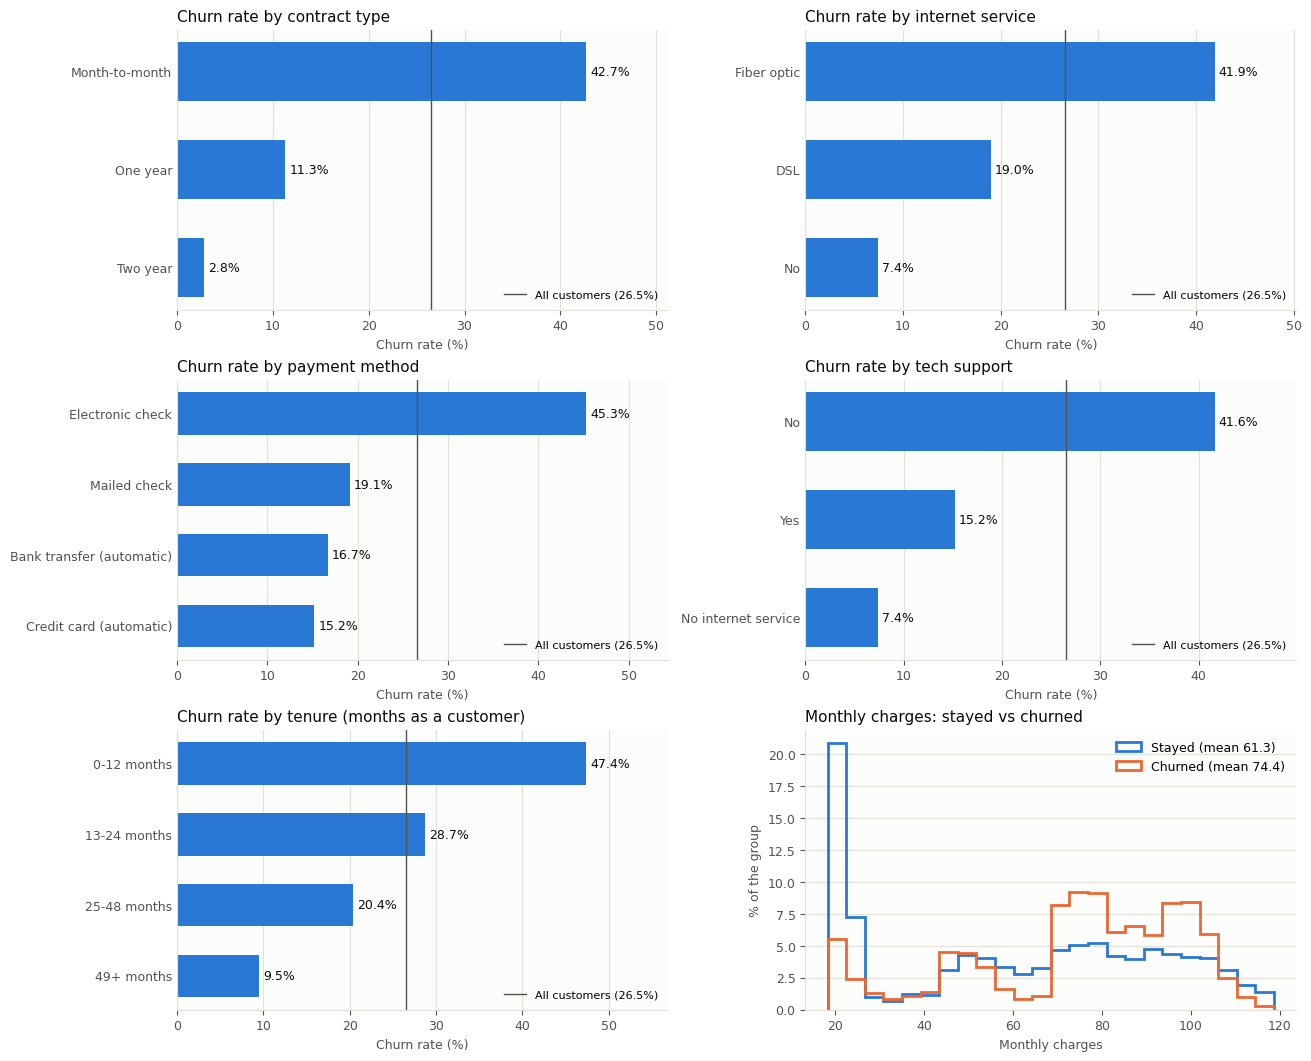

Saved: churn_by_contract.png, churn_by_internetservice.png, churn_by_paymentmethod.png, churn_by_techsupport.png, churn_by_tenure_band.png, monthly_charges_by_churn.png


In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(13, 10.5), layout="constrained")
for ax, (name, table) in zip(axes.flat, tables.items()):
    charts.plot_churn_rate(table, charts.CHART_TITLES[name], ax, overall_rate=overall)
charts.plot_monthly_charges(clean_df, axes.flat[-1])
plt.show()

saved_charts = charts.save_eda_charts(clean_df, config.OUTPUT_DIR / "figures")
print("Saved:", ", ".join(path.name for path in saved_charts))

**Observations in plain English ｜ 觀察結果**

The sentences below are built from the computed tables, so their numbers stay correct if the CSV changes. They describe *who* churned in this sample — none of them proves *why* (no causal claims).

In [24]:
from IPython.display import Markdown, display


def rate(question, group):
    return tables[question].loc[group, "churn_rate_%"]


monthly = analysis.monthly_charges_by_churn(clean_df)["mean"]
bill_by_internet = clean_df.groupby("InternetService")["MonthlyCharges"].mean()
banded = analysis.add_tenure_band(clean_df)
first_year_monthly = (banded.loc[banded["tenure_band"] == "0-12 months", "Contract"] == "Month-to-month").mean() * 100
automatic = (rate("PaymentMethod", "Bank transfer (automatic)") + rate("PaymentMethod", "Credit card (automatic)")) / 2

EDA_OBSERVATIONS = [
    f"**About one customer in four churned ({overall:.1f}%).** The classes are imbalanced: a model that always "
    f"answers \"stays\" would already be right about {100 - overall:.0f}% of the time, so accuracy alone says little.",
    f"**Contract type shows the biggest gap.** Month-to-month customers churned at {rate('Contract', 'Month-to-month'):.1f}%, "
    f"one-year at {rate('Contract', 'One year'):.1f}% and two-year at {rate('Contract', 'Two year'):.1f}%. "
    "Customers who already intend to stay may simply be the ones who sign long contracts.",
    f"**Churn is concentrated in the first year.** {rate('tenure_band', '0-12 months'):.1f}% of customers with 0-12 months "
    f"of tenure churned, vs {rate('tenure_band', '49+ months'):.1f}% after four years. Tenure and contract overlap: "
    f"{first_year_monthly:.0f}% of first-year customers are on month-to-month contracts.",
    f"**Fiber-optic customers churned more** ({rate('InternetService', 'Fiber optic'):.1f}%) than DSL customers "
    f"({rate('InternetService', 'DSL'):.1f}%); customers without internet churned least ({rate('InternetService', 'No'):.1f}%). "
    f"Fiber customers also have higher bills (average {bill_by_internet['Fiber optic']:.0f} vs "
    f"{bill_by_internet['DSL']:.0f} for DSL), so price and service type are tangled.",
    f"**Payment method:** electronic-check payers churned at {rate('PaymentMethod', 'Electronic check'):.1f}%, about "
    f"{rate('PaymentMethod', 'Electronic check') / automatic:.1f}x the rate of customers paying automatically by bank "
    "transfer or credit card.",
    f"**Higher bills go with churn:** churned customers paid {monthly['Churned (1)']:.2f} per month on average vs "
    f"{monthly['Stayed (0)']:.2f} for customers who stayed.",
    f"**Tech support:** customers without it churned at {rate('TechSupport', 'No'):.1f}% vs {rate('TechSupport', 'Yes'):.1f}% "
    "with it - a visible relationship, but not proof that adding support would keep a customer.",
]
display(Markdown("\n".join(f"{number}. {text}" for number, text in enumerate(EDA_OBSERVATIONS, start=1))))

1. **About one customer in four churned (26.5%).** The classes are imbalanced: a model that always answers "stays" would already be right about 73% of the time, so accuracy alone says little.
2. **Contract type shows the biggest gap.** Month-to-month customers churned at 42.7%, one-year at 11.3% and two-year at 2.8%. Customers who already intend to stay may simply be the ones who sign long contracts.
3. **Churn is concentrated in the first year.** 47.4% of customers with 0-12 months of tenure churned, vs 9.5% after four years. Tenure and contract overlap: 91% of first-year customers are on month-to-month contracts.
4. **Fiber-optic customers churned more** (41.9%) than DSL customers (19.0%); customers without internet churned least (7.4%). Fiber customers also have higher bills (average 92 vs 58 for DSL), so price and service type are tangled.
5. **Payment method:** electronic-check payers churned at 45.3%, about 2.8x the rate of customers paying automatically by bank transfer or credit card.
6. **Higher bills go with churn:** churned customers paid 74.44 per month on average vs 61.27 for customers who stayed.
7. **Tech support:** customers without it churned at 41.6% vs 15.2% with it - a visible relationship, but not proof that adding support would keep a customer.

> ✅ **Session 1 checkpoint** — the raw CSV loads from a configurable path, the validation report explains every data issue in plain English, the cleaned table passes its checks, and there are seven evidence-based observations (they go into the README in Task 14).

# 2 · Session 2 — Machine-learning pipeline
**Goal:** turn the cleaned dataset into a reproducible classification experiment.（建立可重現的分類實驗）

## Task 6 — Define features and target ｜ 特徵與目標

`split_features_target()` (in `preprocessing.py`) selects the 19 feature columns **by name** from `config.FEATURE_COLUMNS`. The effect is the same as the brief's `drop(columns=["Churn", "customerID"])`, but safer: `customerID`, `Churn` or an unexpected extra column in a future CSV can never slip into the features. The IDs come back separately so they can label the predictions.

In [25]:
from src.preprocessing import split_features_target

X, y, customer_ids = split_features_target(clean_df)
print("X:", X.shape, "| y:", y.shape, "| customer IDs:", customer_ids.shape)
print("customerID in X?", "customerID" in X.columns, "| Churn in X?", "Churn" in X.columns)
print("Target values:", y.value_counts().to_dict(), "\n")
for group, columns in [("numeric (scaled)", config.NUMERIC_FEATURES),
                       ("binary (as is)", config.BINARY_FEATURES),
                       ("categorical (one-hot)", config.CATEGORICAL_FEATURES)]:
    print(f"{group:<22}{len(columns):>3}: {', '.join(columns)}")

X: (7043, 19) | y: (7043,) | customer IDs: (7043,)
customerID in X? False | Churn in X? False
Target values: {0: 5174, 1: 1869} 

numeric (scaled)        3: tenure, MonthlyCharges, TotalCharges
binary (as is)          1: SeniorCitizen
categorical (one-hot)  15: gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod


## Task 7 — Train/test split ｜ 切分訓練集與測試集

80 % of the customers train the model and 20 % are held back to measure performance on customers it has never seen. `random_state=42` makes the split identical on every run (reproducible), and `stratify=y` keeps the same churn share in both parts — important because churners are the minority class. The customer IDs are split together with their rows.

In [26]:
from src.preprocessing import split_train_test

X_train, X_test, y_train, y_test, ids_train, ids_test = split_train_test(X, y, customer_ids)
pd.DataFrame({
    "customers": [len(y), len(y_train), len(y_test)],
    "churners": [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
    "churn_rate_%": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=["all", "train (80%)", "test (20%)"]).round(2)

,customers,churners,churn_rate_%
all,7043,1869,26.54
train (80%),5634,1495,26.54
test (20%),1409,374,26.54


## Task 8 — Build the classifier ｜ 建立分類模型

`build_model()` in `src/model.py` returns a scikit-learn **Pipeline** with two stages:

1. **`preprocessor`** — a `ColumnTransformer` from `preprocessing.build_preprocessor()`:
   * `StandardScaler` on `tenure`, `MonthlyCharges`, `TotalCharges` → mean 0 and standard deviation 1, so the three numbers are on comparable scales for the regression;
   * `SeniorCitizen` passes through unchanged (already 0/1);
   * `OneHotEncoder(handle_unknown="ignore")` on the 15 text columns → one 0/1 column per category (e.g. `Contract_Two year`); a category never seen in training becomes all zeros instead of an error.
2. **`classifier`** — `LogisticRegression(max_iter=1000)` learns one weight per encoded column and turns the weighted sum into a churn probability between 0 and 1; a probability of 0.5 or more means "predicted churn". `max_iter=1000` gives the solver enough iterations to converge.

`fit()` learns the scaler means, the category lists and the weights **from the training rows only**; `predict()` re-applies exactly those learned steps to any new rows. That is why the pipeline prevents train/test leakage — it is not a magic command.

In [27]:
%%writefile src/model.py
"""Build, train and use the churn classifiers.

Each model is a scikit-learn Pipeline: the preprocessor (scale + one-hot
encode) followed by the classifier. Whatever the preprocessor learns from the
training rows is applied unchanged to every row we predict on.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from src import config
from src.preprocessing import build_preprocessor

MODEL_NAMES = ("logistic_regression", "decision_tree")


def build_model(model_name: str = config.PRIMARY_MODEL) -> Pipeline:
    """An untrained preprocessing + classifier pipeline."""
    if model_name == "logistic_regression":
        classifier = LogisticRegression(**config.LOGISTIC_REGRESSION_PARAMS)
    elif model_name == "decision_tree":
        classifier = DecisionTreeClassifier(random_state=config.RANDOM_STATE, **config.DECISION_TREE_PARAMS)
    else:
        raise ValueError(f"Unknown model '{model_name}'. Choose from: {', '.join(MODEL_NAMES)}")
    return Pipeline([("preprocessor", build_preprocessor()), ("classifier", classifier)])


def train_model(X_train: pd.DataFrame, y_train: pd.Series, model_name: str = config.PRIMARY_MODEL) -> Pipeline:
    """Fit the pipeline on the training rows only."""
    model = build_model(model_name)
    model.fit(X_train, y_train)
    return model


def predict(model: Pipeline, X: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Predicted class (1 = churn) and churn probability for every row of X."""
    churn_column = list(model.classes_).index(1)
    return model.predict(X), model.predict_proba(X)[:, churn_column]


def feature_weights(model: Pipeline) -> pd.DataFrame:
    """What the fitted model learned per encoded feature, strongest first.

    Logistic Regression: coefficient (> 0 pushes towards churn, < 0 away from it).
    Decision Tree: importance (how much the feature is used to split customers).
    """
    names = model.named_steps["preprocessor"].get_feature_names_out()
    classifier = model.named_steps["classifier"]
    if hasattr(classifier, "coef_"):
        table = pd.DataFrame({"feature": names, "coefficient": classifier.coef_[0]})
        order = table["coefficient"].abs().sort_values(ascending=False).index
    else:
        table = pd.DataFrame({"feature": names, "importance": classifier.feature_importances_})
        order = table["importance"].sort_values(ascending=False).index
    return table.loc[order].reset_index(drop=True)

Writing src/model.py


In [28]:
from src.model import feature_weights, predict, train_model

lr_model = train_model(X_train, y_train, "logistic_regression")
encoded_names = lr_model.named_steps["preprocessor"].get_feature_names_out()
print(f"{X_train.shape[1]} feature columns -> {len(encoded_names)} model inputs after scaling + one-hot encoding")
lr_model

19 feature columns -> 45 model inputs after scaling + one-hot encoding


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('binary', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differen

## Task 9 — Evaluate the model ｜ 模型評估

`src/evaluation.py` computes the metrics with churn (1) as the *positive* class:

| Metric | Meaning in this problem |
|---|---|
| **Accuracy** | share of all test customers labelled correctly |
| **Precision** | of the customers flagged as "will churn", the share who really churn — low precision = retention offers wasted on customers who would have stayed |
| **Recall** | of the customers who really churn, the share the model catches — low recall = customers lost without anyone contacting them |
| **F1** | harmonic mean of precision and recall — high only when both are |
| **Confusion matrix** | the four counts behind all of the above |

A **false negative** is a customer who actually churned but was predicted to stay. For a retention team it is the costliest mistake: nobody contacts that customer before they leave.

In [29]:
%%writefile src/evaluation.py
"""Metrics, the confusion matrix and the output files."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

from src import config

PREDICTION_COLUMNS = ["customerID", "actual_churn", "predicted_churn", "churn_probability", "risk_level"]
METRIC_NAMES = ["accuracy", "precision", "recall", "f1"]


def calculate_metrics(y_true, y_pred) -> dict:
    """Accuracy, precision, recall and F1 (churn = positive class) plus the confusion counts."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


def confusion_matrix_table(metrics: dict) -> pd.DataFrame:
    """2 x 2 table: rows = what really happened, columns = what the model predicted."""
    return pd.DataFrame(
        [[metrics["true_negatives"], metrics["false_positives"]],
         [metrics["false_negatives"], metrics["true_positives"]]],
        index=["Actual: stayed", "Actual: churned"],
        columns=["Predicted: stay", "Predicted: churn"],
    )


def format_metrics(metrics: dict) -> str:
    """Aligned metric lines for the console."""
    return "\n".join([
        f"Accuracy : {metrics['accuracy']:.3f}",
        f"Precision: {metrics['precision']:.3f}",
        f"Recall   : {metrics['recall']:.3f}",
        f"F1 Score : {metrics['f1']:.3f}",
    ])


def explain_metrics(metrics: dict) -> list[str]:
    """The metrics in business language (churn = the case we want to find)."""
    tp, fp = metrics["true_positives"], metrics["false_positives"]
    fn, tn = metrics["false_negatives"], metrics["true_negatives"]
    return [
        f"Accuracy {metrics['accuracy']:.1%}: {tp + tn:,} of the {tp + fp + fn + tn:,} test customers "
        "are labelled correctly.",
        f"Precision {metrics['precision']:.1%}: of the {tp + fp:,} customers flagged as likely to churn, "
        f"{tp:,} really churned.",
        f"Recall {metrics['recall']:.1%}: of the {tp + fn:,} customers who really churned, "
        f"the model caught {tp:,}.",
        f"False negatives: {fn:,} customers churned although the model said they would stay - "
        "a retention team would never have contacted them.",
        f"False positives: {fp:,} customers who stayed were flagged - the cost is an unneeded retention offer.",
    ]


def compare_models(results: dict) -> pd.DataFrame:
    """One row per model with the four headline metrics."""
    return pd.DataFrame(results).T[METRIC_NAMES].astype(float).round(3)


def build_predictions_frame(customer_ids, y_true, y_pred, churn_probability) -> pd.DataFrame:
    """The predictions table, highest churn risk first."""
    predictions = pd.DataFrame({
        "customerID": np.asarray(customer_ids),
        "actual_churn": np.asarray(y_true, dtype=int),
        "predicted_churn": np.asarray(y_pred, dtype=int),
        "churn_probability": np.round(np.asarray(churn_probability, dtype=float), 4),
    })
    predictions["risk_level"] = pd.cut(
        predictions["churn_probability"], bins=config.RISK_BINS,
        labels=config.RISK_LABELS, include_lowest=True,
    ).astype(str)
    return predictions.sort_values("churn_probability", ascending=False, ignore_index=True)


def risk_summary(predictions: pd.DataFrame) -> pd.DataFrame:
    """Customers and actual churn rate per risk band - does the risk score rank customers well?"""
    summary = predictions.groupby("risk_level")["actual_churn"].agg(["size", "mean"])
    summary.columns = ["customers", "actual_churn_%"]
    summary["actual_churn_%"] = (summary["actual_churn_%"] * 100).round(1)
    return summary.loc[[label for label in config.RISK_LABELS if label in summary.index]]


def save_predictions(predictions: pd.DataFrame, path: str | Path) -> Path:
    """Write the predictions table as CSV."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    predictions.to_csv(path, index=False)
    return path


def save_metrics(summary: dict, path: str | Path) -> Path:
    """Write the metrics (and the settings that produced them) as JSON."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
    return path

Writing src/evaluation.py


In [30]:
from src import evaluation

lr_pred, lr_proba = predict(lr_model, X_test)
lr_metrics = evaluation.calculate_metrics(y_test, lr_pred)
print(evaluation.format_metrics(lr_metrics))
print(f"\nBaseline - always predicting 'stays': accuracy {1 - y_test.mean():.3f}, recall 0.000")
evaluation.confusion_matrix_table(lr_metrics)

Accuracy : 0.806
Precision: 0.657
Recall   : 0.559
F1 Score : 0.604

Baseline - always predicting 'stays': accuracy 0.735, recall 0.000


,Predicted: stay,Predicted: churn
Actual: stayed,926,109
Actual: churned,165,209


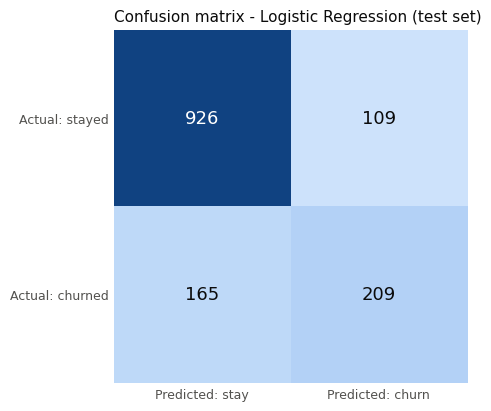

- Accuracy 80.6%: 1,135 of the 1,409 test customers are labelled correctly.
- Precision 65.7%: of the 318 customers flagged as likely to churn, 209 really churned.
- Recall 55.9%: of the 374 customers who really churned, the model caught 209.
- False negatives: 165 customers churned although the model said they would stay - a retention team would never have contacted them.
- False positives: 109 customers who stayed were flagged - the cost is an unneeded retention offer.


In [31]:
fig, ax = plt.subplots(figsize=(5.5, 4), layout="constrained")
charts.plot_confusion_matrix(evaluation.confusion_matrix_table(lr_metrics), ax,
                             title="Confusion matrix - Logistic Regression (test set)")
plt.show()
for line in evaluation.explain_metrics(lr_metrics):
    print("-", line)

**In plain words.** Accuracy looks good, but the baseline shows why it is not enough: answering "stays" for everybody is already about as accurate and finds no churner at all. Precision and recall tell the real story (lines above): the model finds only part of the churners, and some of the customers it flags would have stayed. Where to set that balance is a business decision — if a missed churner costs more than an unneeded offer, lowering the 0.5 threshold raises recall at the price of precision (see *Future improvements* in the README).

## Task 10 — Create `predictions.csv` ｜ 輸出預測結果

One row per test customer, highest churn risk first:

| Column | Meaning |
|---|---|
| `customerID` | original customer identifier |
| `actual_churn` | known outcome in the test set (1 = churned) |
| `predicted_churn` | the model's class (1 = predicted to churn, probability ≥ 0.5) |
| `churn_probability` | the model's risk score between 0 and 1 |
| `risk_level` | Low (≤ 0.3), Medium (0.3–0.6), High (> 0.6) — simple bands for prioritising outreach, not calibrated business thresholds |

In [32]:
predictions = evaluation.build_predictions_frame(ids_test, y_test, lr_pred, lr_proba)
predictions_path = evaluation.save_predictions(predictions, config.OUTPUT_DIR / "predictions.csv")
print("Saved:", predictions_path.relative_to(config.PROJECT_ROOT), "|", len(predictions), "rows")
predictions.head(10)

Saved: output/predictions.csv | 1409 rows


,customerID,actual_churn,predicted_churn,churn_probability,risk_level
0,5178-LMXOP,1,1,0.8549,High
1,0295-PPHDO,1,1,0.8321,High
2,6861-XWTWQ,1,1,0.8286,High
3,8884-ADFVN,1,1,0.8218,High
4,1069-XAIEM,1,1,0.8188,High
5,2545-EBUPK,0,1,0.8178,High
6,6023-YEBUP,1,1,0.8176,High
7,9057-SIHCH,1,1,0.8173,High
8,1400-MMYXY,1,1,0.8163,High
9,6630-UJZMY,0,1,0.8125,High


In [33]:
# Does the risk score rank customers well? Actual churn rate inside each band:
evaluation.risk_summary(predictions)

,customers,actual_churn_%
risk_level,,
Low,866,10.6
Medium,334,39.5
High,209,71.8


The bands behave like a risk score should: the actual churn rate rises steeply from Low to High, so a retention team working down the list from the top reaches real churners first.

## Optional challenge — second model: Decision Tree ｜ 加分：決策樹比較

Same split, same preprocessing, different classifier. The tree is limited to `max_depth=5` and `min_samples_leaf=20`; the overfitting check below shows why.

In [34]:
dt_model = train_model(X_train, y_train, "decision_tree")
dt_pred, dt_proba = predict(dt_model, X_test)
results = {
    "logistic_regression": lr_metrics,
    "decision_tree": evaluation.calculate_metrics(y_test, dt_pred),
}
evaluation.compare_models(results)

,accuracy,precision,recall,f1
logistic_regression,0.806,0.657,0.559,0.604
decision_tree,0.798,0.635,0.567,0.599


In [35]:
import numpy as np

from src.model import build_model

# Overfitting check: accuracy on the training rows vs on unseen test rows
unlimited_tree = build_model("decision_tree").set_params(classifier__max_depth=None, classifier__min_samples_leaf=1)
unlimited_tree.fit(X_train, y_train)
overfitting = pd.DataFrame({
    name: {"train accuracy": fitted.score(X_train, y_train), "test accuracy": fitted.score(X_test, y_test)}
    for name, fitted in [("logistic_regression", lr_model),
                         ("decision_tree (depth 5)", dt_model),
                         ("decision_tree (no depth limit)", unlimited_tree)]
}).T
overfitting["gap"] = overfitting["train accuracy"] - overfitting["test accuracy"]
overfitting = overfitting.round(3)

lr_m, dt_m = results["logistic_regression"], results["decision_tree"]
print(f"Churners caught (TP): LR {lr_m['true_positives']} vs tree {dt_m['true_positives']} | "
      f"false alarms (FP): LR {lr_m['false_positives']} vs tree {dt_m['false_positives']}")
print(f"Distinct risk scores for {len(X_test):,} test customers: "
      f"LR {len(np.unique(lr_proba)):,} vs tree {len(np.unique(dt_proba))}")
overfitting

Churners caught (TP): LR 209 vs tree 212 | false alarms (FP): LR 109 vs tree 122
Distinct risk scores for 1,409 test customers: LR 1,407 vs tree 30


,train accuracy,test accuracy,gap
logistic_regression,0.806,0.806,0.000
decision_tree (depth 5),0.803,0.798,0.004
decision_tree (no depth limit),0.998,0.726,0.272


In [36]:
# What the Logistic Regression learned: the 10 largest weights (> 0 = associated with more churn)
feature_weights(lr_model).head(10).round(3)

,feature,coefficient
0,tenure,-1.250
1,Contract_Two year,-0.771
2,InternetService_DSL,-0.661
3,InternetService_Fiber optic,0.651
4,MonthlyCharges,-0.621
5,Contract_Month-to-month,0.576
6,TotalCharges,0.525
7,PaperlessBilling_No,-0.344
8,StreamingMovies_No internet service,-0.306
9,StreamingTV_No internet service,-0.306


**Trade-off, not just the higher number ｜ 模型取捨**
* The two models score close to each other (table above), so compare recall and precision, not only accuracy: the tree catches a few more churners but raises more false alarms (counts printed above).
* The tree without a depth limit shows **overfitting**: almost perfect on the customers it trained on, clearly worse on new ones. Limiting the depth closes most of that gap.
* A depth-5 tree can only output as many different risk scores as it has leaves, so many customers share one score; the regression gives almost every customer its own probability — better for ranking a call list.
* **Logistic Regression stays the primary model:** at least as good on F1, a smooth risk score, a small train/test gap and weights that can be explained. A tree would be the better pick if the business wanted simple if/then rules.

**Reading the weights.** The largest weights tell the same story as the EDA: longer tenure and two-year contracts go with a *lower* churn probability (negative weights), fiber-optic internet and month-to-month contracts with a *higher* one. Notice that `MonthlyCharges` gets a negative weight although churners pay more on average: the services that make a bill high (fiber, streaming) and `TotalCharges` (roughly tenure × monthly charge) already carry that information. With overlapping features a single weight cannot be read on its own — and none of them is a cause.

> ✅ **Session 2 checkpoint** — a fresh run loads the data, prepares the features, trains the model, evaluates it and writes `output/predictions.csv` without any manual editing.

# 3 · Session 3 — Refactoring, testing, Git & CI/CD
**Goal:** turn the working experiment into a small, maintainable project.（模組化、測試與自動化）

## Task 11 — Refactor into modules ｜ 模組化與 `main.py`

The modules already exist — each one was written in the task that needed it, and no logic is duplicated:

| Module | Responsibility |
|---|---|
| `config.py` | paths, column groups, validation rules, model settings |
| `data_loader.py` | load the CSV (+ optional download), basic input checks |
| `validator.py` | data-quality checks and the validation report |
| `preprocessing.py` | cleaning, feature/target split, train/test split, encoders |
| `analysis.py` · `charts.py` | EDA tables and findings · Matplotlib charts |
| `model.py` | build, train and use the classifiers |
| `evaluation.py` | metrics, confusion matrix, predictions table, output files |
| `pipeline.py` | coordinates the end-to-end workflow |

`run_pipeline()` calls them in the order of the brief's flow and prints a log a non-programmer can follow. `main.py` is the command-line entry point, with `argparse` options for the input and output paths (a bonus item).

In [37]:
%%writefile src/pipeline.py
"""Run the whole workflow end to end.

CSV -> load -> validate -> clean -> explore -> split -> train -> evaluate -> save outputs
"""
from __future__ import annotations

from pathlib import Path

from src import analysis, charts, config, data_loader, evaluation, model, preprocessing, validator


def _relative(path: str | Path) -> str:
    """Show a path relative to the current folder when possible (shorter, no user name)."""
    path = Path(path).resolve()
    try:
        return str(path.relative_to(Path.cwd().resolve()))
    except ValueError:
        return str(path)


def _step(number: int, title: str) -> None:
    print(f"\n[{number}] {title}...")


def run_pipeline(
    input_path: str | Path = config.RAW_DATA_PATH,
    output_dir: str | Path = config.OUTPUT_DIR,
    processed_path: str | Path = config.PROCESSED_DATA_PATH,
    save_charts: bool = True,
) -> dict:
    """Run every stage, print a readable log and write the output files.

    Returns the main intermediate objects so a notebook or a test can inspect them.
    """
    output_dir = Path(output_dir)
    processed_path = Path(processed_path)
    print("=" * 44)
    print("TELCO CUSTOMER CHURN ANALYSIS")
    print("=" * 44)

    _step(1, "Loading data")
    raw_df = data_loader.load_raw_data(input_path)
    print(f"Rows loaded: {len(raw_df)} | Columns: {raw_df.shape[1]} | File: {_relative(input_path)}")

    _step(2, "Validating data")
    report = validator.validate_raw_data(raw_df)
    print(report.to_text())
    print(f"Saved: {_relative(validator.save_report(report, output_dir / 'validation_report.txt'))}")
    if report.missing_columns:
        raise ValueError(f"Cannot continue - required columns are missing: {report.missing_columns}")

    _step(3, "Cleaning data")
    clean_df, notes = preprocessing.clean_data(raw_df)
    for note in notes:
        print(f"- {note}")
    problems = validator.check_clean_data(clean_df)
    if problems:
        raise ValueError("Cleaned data failed its checks: " + "; ".join(problems))
    processed_path.parent.mkdir(parents=True, exist_ok=True)
    clean_df.to_csv(processed_path, index=False)
    print(f"Cleaned data checks: PASS ({len(clean_df)} rows) | Saved: {_relative(processed_path)}")

    _step(4, "Exploring data")
    for finding in analysis.describe_findings(clean_df):
        print(f"- {finding}")
    if save_charts:
        chart_paths = charts.save_eda_charts(clean_df, output_dir / "figures")
        print(f"Saved {len(chart_paths)} charts to: {_relative(output_dir / 'figures')}")

    _step(5, "Training models")
    X, y, ids = preprocessing.split_features_target(clean_df)
    X_train, X_test, y_train, y_test, _, ids_test = preprocessing.split_train_test(X, y, ids)
    print(f"Features: {X.shape[1]} columns (customerID and Churn are not features)")
    print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)} "
          f"(test_size={config.TEST_SIZE}, random_state={config.RANDOM_STATE}, stratified)")
    models = {name: model.train_model(X_train, y_train, name) for name in model.MODEL_NAMES}
    print(f"Models trained: {', '.join(models)}")

    _step(6, "Evaluating models")
    outputs = {name: model.predict(fitted, X_test) for name, fitted in models.items()}
    results = {name: evaluation.calculate_metrics(y_test, predicted) for name, (predicted, _) in outputs.items()}
    primary = results[config.PRIMARY_MODEL]
    print(f"Primary model: {config.PRIMARY_MODEL}")
    print(evaluation.format_metrics(primary))
    print("Confusion matrix (test set):")
    print(evaluation.confusion_matrix_table(primary).to_string())
    print("Model comparison (test set):")
    print(evaluation.compare_models(results).to_string())
    if save_charts:
        charts.save_confusion_matrix(evaluation.confusion_matrix_table(primary),
                                     output_dir / "figures" / "confusion_matrix.png")

    _step(7, "Writing predictions")
    predicted, probability = outputs[config.PRIMARY_MODEL]
    predictions = evaluation.build_predictions_frame(ids_test, y_test, predicted, probability)
    print(f"Saved: {_relative(evaluation.save_predictions(predictions, output_dir / 'predictions.csv'))}")
    summary = {
        "primary_model": config.PRIMARY_MODEL,
        "split": {"test_size": config.TEST_SIZE, "random_state": config.RANDOM_STATE, "stratified": True,
                  "train_rows": len(X_train), "test_rows": len(X_test)},
        "models": results,
    }
    print(f"Saved: {_relative(evaluation.save_metrics(summary, output_dir / 'metrics.json'))}")

    print("\nPipeline completed successfully.")
    return {"report": report, "clean_df": clean_df, "models": models, "metrics": results, "predictions": predictions}

Writing src/pipeline.py


In [38]:
%%writefile main.py
"""Command-line entry point for the churn pipeline.

    python main.py --input data/raw/Telco-Customer-Churn.csv
"""
from __future__ import annotations

import argparse
import sys

from src import config
from src.data_loader import download_dataset
from src.pipeline import run_pipeline


def parse_args(argv: list[str] | None = None) -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Validate the Telco churn CSV, train churn models and write predictions."
    )
    parser.add_argument("--input", default=str(config.RAW_DATA_PATH),
                        help="raw CSV file (default: data/raw/Telco-Customer-Churn.csv)")
    parser.add_argument("--output-dir", default=str(config.OUTPUT_DIR),
                        help="folder for the report, metrics, predictions and charts (default: output/)")
    parser.add_argument("--download", action="store_true",
                        help="download the IBM CSV to --input first if the file is missing")
    parser.add_argument("--no-charts", action="store_true", help="skip writing the PNG charts")
    return parser.parse_args(argv)


def main(argv: list[str] | None = None) -> int:
    args = parse_args(argv)
    try:
        if args.download:
            download_dataset(args.input)
        run_pipeline(input_path=args.input, output_dir=args.output_dir, save_charts=not args.no_charts)
    except (OSError, ValueError) as error:  # missing file, failed download, invalid data
        print(f"ERROR: {error}", file=sys.stderr)
        return 1
    return 0


if __name__ == "__main__":
    sys.exit(main())

Writing main.py


In [39]:
import subprocess


def run(*args):
    # Run a command with this notebook's Python interpreter, from the project root
    return subprocess.run([sys.executable, *args], cwd=PROJECT_ROOT, capture_output=True, text=True)


print(run("main.py", "--help").stdout)

usage: main.py [-h] [--input INPUT] [--output-dir OUTPUT_DIR] [--download]
               [--no-charts]

Validate the Telco churn CSV, train churn models and write predictions.

options:
  -h, --help            show this help message and exit
  --input INPUT         raw CSV file (default: data/raw/Telco-Customer-
                        Churn.csv)
  --output-dir OUTPUT_DIR
                        folder for the report, metrics, predictions and charts
                        (default: output/)
  --download            download the IBM CSV to --input first if the file is
                        missing
  --no-charts           skip writing the PNG charts



In [40]:
cli = run("main.py", "--input", "data/raw/Telco-Customer-Churn.csv")
print(cli.stdout)
if cli.stderr:
    print(cli.stderr)
assert cli.returncode == 0, "main.py failed - see the error above"

TELCO CUSTOMER CHURN ANALYSIS

[1] Loading data...
Rows loaded: 7043 | Columns: 21 | File: data/raw/Telco-Customer-Churn.csv

[2] Validating data...
DATA VALIDATION REPORT
----------------------
Rows: 7043
Columns: 21
Required columns missing: none
Column types: object (18), int64 (2), float64 (1)
Numeric columns stored as text: TotalCharges
Duplicate customer IDs: 0
Missing-value fields: TotalCharges (11)
Target labels (Churn): No (5174), Yes (1869)
Invalid target values: none
TotalCharges conversion issues: 11 blank/non-numeric value(s); tenure of those customers: 0
Negative numeric values: none
Tenure outside 0-120 months: 0
Unexpected categorical values: none
Service consistency issues: 0
Overall status: REVIEW
To handle before modelling:
  - Missing or blank values in: TotalCharges (11)
  - TotalCharges has 11 value(s) that are not numbers
Saved: output/validation_report.txt

[3] Cleaning data...
- TotalCharges converted from text to float; 11 blank value(s) filled with MonthlyCha

In [41]:
import json
import math

# The command-line run must reproduce the notebook's numbers: same code, same random_state
cli_results = json.loads((config.OUTPUT_DIR / "metrics.json").read_text(encoding="utf-8"))["models"]
same = all(math.isclose(cli_results[name][key], value) for name in results for key, value in results[name].items())
print("main.py metrics identical to the notebook run:", same)
assert same

main.py metrics identical to the notebook run: True


## Task 12 — Unit tests ｜ 單元測試

Five test files (the brief asks for at least five tests). They run on a 60-row **synthetic sample** built in `tests/conftest.py` — same format as the IBM file, including two blank `TotalCharges` for tenure-0 customers — so they need no download and behave the same way in CI.

Every test the brief recommends is there: required columns · Churn labels before encoding · duplicate IDs detected · TotalCharges numeric after cleaning · no negative charges · model trains on a small sample · predictions contain only valid classes · prediction output has the required columns. Extra tests cover a hand-checked metrics example, a clear error for a missing file, reproducible stratified splitting, and an end-to-end run proving the raw CSV is byte-for-byte unchanged.

In [42]:
%%writefile tests/conftest.py
"""Shared test data: 60 fake customers in the raw IBM file format.

The tests never read the real CSV, so they run the same way on any machine
and in GitHub Actions.
"""
import numpy as np
import pandas as pd
import pytest


@pytest.fixture
def raw_sample() -> pd.DataFrame:
    rng = np.random.default_rng(seed=7)
    n = 60
    yes_no = ["Yes", "No"]
    internet = rng.choice(["DSL", "Fiber optic", "No"], size=n)
    phone = rng.choice(yes_no, size=n, p=[0.9, 0.1])

    def internet_addon():
        return np.where(internet == "No", "No internet service", rng.choice(yes_no, size=n))

    tenure = rng.integers(1, 73, size=n)
    tenure[:2] = 0  # two brand-new customers, as in the real file ...
    monthly = rng.uniform(18, 120, size=n).round(2)
    total = (monthly * tenure).round(2).astype(str)
    total[:2] = " "  # ... whose TotalCharges is a blank string, as in the real file

    return pd.DataFrame({
        "customerID": [f"{i:04d}-TEST" for i in range(n)],
        "gender": rng.choice(["Male", "Female"], size=n),
        "SeniorCitizen": rng.choice([0, 1], size=n, p=[0.8, 0.2]),
        "Partner": rng.choice(yes_no, size=n),
        "Dependents": rng.choice(yes_no, size=n),
        "tenure": tenure,
        "PhoneService": phone,
        "MultipleLines": np.where(phone == "No", "No phone service", rng.choice(yes_no, size=n)),
        "InternetService": internet,
        "OnlineSecurity": internet_addon(),
        "OnlineBackup": internet_addon(),
        "DeviceProtection": internet_addon(),
        "TechSupport": internet_addon(),
        "StreamingTV": internet_addon(),
        "StreamingMovies": internet_addon(),
        "Contract": rng.choice(["Month-to-month", "One year", "Two year"], size=n),
        "PaperlessBilling": rng.choice(yes_no, size=n),
        "PaymentMethod": rng.choice(
            ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"],
            size=n,
        ),
        "MonthlyCharges": monthly,
        "TotalCharges": total,
        "Churn": np.where(np.arange(n) % 3 == 0, "Yes", "No"),  # 20 churners, 40 stayers
    })

Writing tests/conftest.py


In [43]:
%%writefile tests/test_data_loader.py
import pandas as pd
import pytest

from src import config
from src.data_loader import load_raw_data
from src.validator import find_duplicate_ids, find_invalid_values, find_missing_columns


def test_load_raw_data_reads_every_row_and_column(tmp_path, raw_sample):
    csv_path = tmp_path / "customers.csv"
    raw_sample.to_csv(csv_path, index=False)

    loaded = load_raw_data(csv_path)

    assert loaded.shape == raw_sample.shape
    assert list(loaded.columns) == list(raw_sample.columns)
    # loaded as stored: the blank cells keep TotalCharges a text column
    assert not pd.api.types.is_numeric_dtype(loaded["TotalCharges"])


def test_load_raw_data_gives_a_clear_error_for_a_missing_file(tmp_path):
    with pytest.raises(FileNotFoundError, match="Input file not found"):
        load_raw_data(tmp_path / "missing.csv")


@pytest.mark.skipif(not config.RAW_DATA_PATH.exists(), reason="real CSV not downloaded")
def test_real_dataset_matches_the_data_dictionary():
    df = load_raw_data(config.RAW_DATA_PATH)

    assert find_missing_columns(df) == []
    assert find_duplicate_ids(df) == []
    assert find_invalid_values(df["Churn"], config.TARGET_LABELS) == {}

Writing tests/test_data_loader.py


In [44]:
%%writefile tests/test_validator.py
import pandas as pd

from src import config
from src.validator import (
    count_missing_values,
    find_duplicate_ids,
    find_invalid_values,
    find_missing_columns,
    find_unexpected_categories,
    validate_raw_data,
)


def test_required_columns_exist(raw_sample):
    assert find_missing_columns(raw_sample) == []


def test_a_missing_required_column_is_reported(raw_sample):
    report = validate_raw_data(raw_sample.drop(columns=["Contract"]))

    assert report.missing_columns == ["Contract"]
    assert report.status == "REVIEW"


def test_churn_contains_only_expected_labels_before_encoding(raw_sample):
    assert find_invalid_values(raw_sample["Churn"], config.TARGET_LABELS) == {}

    broken = raw_sample.copy()
    broken.loc[0, "Churn"] = "Maybe"
    assert find_invalid_values(broken["Churn"], config.TARGET_LABELS) == {"Maybe": 1}


def test_duplicate_customer_ids_are_detected(raw_sample):
    assert find_duplicate_ids(raw_sample) == []

    with_duplicate = pd.concat([raw_sample, raw_sample.iloc[[5]]], ignore_index=True)
    assert find_duplicate_ids(with_duplicate) == [raw_sample.loc[5, "customerID"]]


def test_blank_total_charges_are_reported_although_pandas_sees_no_nan(raw_sample):
    assert raw_sample["TotalCharges"].isna().sum() == 0  # the trap: " " is not NaN

    assert count_missing_values(raw_sample) == {"TotalCharges": 2}
    report = validate_raw_data(raw_sample)
    assert report.total_charges_issues == 2
    assert report.total_charges_issue_tenures == [0]


def test_negative_charges_and_impossible_tenure_are_detected(raw_sample):
    broken = raw_sample.copy()
    broken.loc[3, "MonthlyCharges"] = -10.0
    broken.loc[4, "tenure"] = 999

    report = validate_raw_data(broken)

    assert report.negative_values == {"MonthlyCharges": 1}
    assert report.out_of_range_tenure == 1


def test_unexpected_category_values_are_reported(raw_sample):
    broken = raw_sample.copy()
    broken.loc[0, "Contract"] = "Three year"

    assert find_unexpected_categories(broken) == {"Contract": {"Three year": 1}}


def test_report_passes_once_nothing_needs_fixing(raw_sample):
    fixed = raw_sample.copy()
    fixed.loc[:1, "TotalCharges"] = "0"

    report = validate_raw_data(fixed)

    assert report.issues == []
    assert report.status == "PASS"

Writing tests/test_validator.py


In [45]:
%%writefile tests/test_preprocessing.py
import pandas as pd

from src.preprocessing import clean_data, split_features_target, split_train_test


def test_total_charges_is_numeric_after_cleaning(raw_sample):
    clean, _ = clean_data(raw_sample)

    assert pd.api.types.is_float_dtype(clean["TotalCharges"])
    assert clean["TotalCharges"].notna().all()
    # the blank values belonged to tenure-0 customers, so they become 0.0
    assert (clean.loc[clean["tenure"] == 0, "TotalCharges"] == 0).all()


def test_cleaned_data_has_no_negative_charges(raw_sample):
    clean, _ = clean_data(raw_sample)

    assert (clean[["MonthlyCharges", "TotalCharges"]] >= 0).all().all()


def test_churn_is_encoded_as_1_for_yes_and_0_for_no(raw_sample):
    clean, _ = clean_data(raw_sample)

    assert set(clean["Churn"].unique()) == {0, 1}
    assert clean["Churn"].sum() == (raw_sample["Churn"] == "Yes").sum()


def test_cleaning_never_modifies_the_raw_dataframe(raw_sample):
    before = raw_sample.copy(deep=True)

    clean_data(raw_sample)

    pd.testing.assert_frame_equal(raw_sample, before)


def test_duplicate_ids_and_invalid_labels_are_removed(raw_sample):
    dirty = pd.concat([raw_sample, raw_sample.iloc[[0]]], ignore_index=True)  # one repeated customer
    dirty.loc[1, "Churn"] = "Unknown"  # one row without a usable label

    clean, _ = clean_data(dirty)

    assert len(clean) == len(raw_sample) - 1
    assert clean["customerID"].is_unique


def test_customer_id_is_kept_out_of_the_features(raw_sample):
    clean, _ = clean_data(raw_sample)

    X, y, ids = split_features_target(clean)

    assert "customerID" not in X.columns
    assert "Churn" not in X.columns
    assert list(ids) == list(clean["customerID"])


def test_train_test_split_is_reproducible_and_stratified(raw_sample):
    clean, _ = clean_data(raw_sample)
    X, y, ids = split_features_target(clean)

    _, _, _, y_test, _, ids_test = split_train_test(X, y, ids)
    _, _, _, _, _, ids_test_again = split_train_test(X, y, ids)

    assert list(ids_test) == list(ids_test_again)  # same customers every run
    assert abs(y_test.mean() - y.mean()) < 0.05  # churn share kept in the test set

Writing tests/test_preprocessing.py


In [46]:
%%writefile tests/test_model.py
import numpy as np
import pytest

from src.evaluation import PREDICTION_COLUMNS, build_predictions_frame, calculate_metrics
from src.model import MODEL_NAMES, build_model, predict, train_model
from src.preprocessing import clean_data, split_features_target, split_train_test


@pytest.fixture
def split_sample(raw_sample):
    clean, _ = clean_data(raw_sample)
    return split_train_test(*split_features_target(clean))


@pytest.mark.parametrize("model_name", MODEL_NAMES)
def test_model_trains_on_a_small_sample_and_predicts_valid_classes(split_sample, model_name):
    X_train, X_test, y_train, _, _, _ = split_sample

    fitted = train_model(X_train, y_train, model_name)
    predicted, probability = predict(fitted, X_test)

    assert len(predicted) == len(X_test)
    assert set(np.unique(predicted)) <= {0, 1}
    assert np.all((probability >= 0) & (probability <= 1))


def test_an_unknown_model_name_is_rejected():
    with pytest.raises(ValueError, match="Unknown model"):
        build_model("random_forest")


def test_prediction_output_contains_the_required_columns(split_sample):
    X_train, X_test, y_train, y_test, _, ids_test = split_sample
    fitted = train_model(X_train, y_train)
    predicted, probability = predict(fitted, X_test)

    output = build_predictions_frame(ids_test, y_test, predicted, probability)

    assert list(output.columns) == PREDICTION_COLUMNS
    assert len(output) == len(X_test)
    assert set(output["customerID"]) == set(ids_test)
    assert output["churn_probability"].is_monotonic_decreasing  # highest risk first


def test_metrics_match_a_hand_calculation():
    # 3 true positives, 1 false negative, 2 false positives, 2 true negatives
    y_true = [1, 1, 1, 1, 0, 0, 0, 0]
    y_pred = [1, 1, 1, 0, 1, 1, 0, 0]

    metrics = calculate_metrics(y_true, y_pred)

    assert metrics["accuracy"] == pytest.approx(5 / 8)
    assert metrics["precision"] == pytest.approx(3 / 5)
    assert metrics["recall"] == pytest.approx(3 / 4)
    assert metrics["f1"] == pytest.approx(2 / 3)
    assert metrics["false_negatives"] == 1

Writing tests/test_model.py


In [47]:
%%writefile tests/test_pipeline.py
import hashlib

import pandas as pd

from src.charts import save_eda_charts
from src.evaluation import PREDICTION_COLUMNS
from src.pipeline import run_pipeline
from src.preprocessing import clean_data


def _fingerprint(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def test_pipeline_runs_end_to_end_and_leaves_the_raw_csv_untouched(tmp_path, raw_sample):
    raw_csv = tmp_path / "raw.csv"
    raw_sample.to_csv(raw_csv, index=False)
    fingerprint_before = _fingerprint(raw_csv)

    run_pipeline(input_path=raw_csv, output_dir=tmp_path / "output",
                 processed_path=tmp_path / "clean.csv", save_charts=False)

    predictions = pd.read_csv(tmp_path / "output" / "predictions.csv")
    assert list(predictions.columns) == PREDICTION_COLUMNS
    assert (tmp_path / "output" / "validation_report.txt").exists()
    assert (tmp_path / "output" / "metrics.json").exists()
    assert _fingerprint(raw_csv) == fingerprint_before


def test_eda_charts_are_saved_as_png_files(tmp_path, raw_sample):
    clean, _ = clean_data(raw_sample)

    paths = save_eda_charts(clean, tmp_path)

    assert len(paths) >= 3
    assert all(path.suffix == ".png" and path.stat().st_size > 0 for path in paths)

Writing tests/test_pipeline.py


In [48]:
tests = run("-m", "pytest", "-v", "--no-header")
print(tests.stdout)
assert tests.returncode == 0, "Some tests failed - read the output above"

============================= test session starts ==============================
collecting ... collected 25 items

tests/test_data_loader.py::test_load_raw_data_reads_every_row_and_column PASSED [  4%]
tests/test_data_loader.py::test_load_raw_data_gives_a_clear_error_for_a_missing_file PASSED [  8%]
tests/test_data_loader.py::test_real_dataset_matches_the_data_dictionary PASSED [ 12%]
tests/test_model.py::test_model_trains_on_a_small_sample_and_predicts_valid_classes[logistic_regression] PASSED [ 16%]
tests/test_model.py::test_model_trains_on_a_small_sample_and_predicts_valid_classes[decision_tree] PASSED [ 20%]
tests/test_model.py::test_an_unknown_model_name_is_rejected PASSED       [ 24%]
tests/test_model.py::test_prediction_output_contains_the_required_columns PASSED [ 28%]
tests/test_model.py::test_metrics_match_a_hand_calculation PASSED        [ 32%]
tests/test_pipeline.py::test_pipeline_runs_end_to_end_and_leaves_the_raw_csv_untouched PASSED [ 36%]
tests/test_pipeline.py::test_e

> 💡 **Demo tip:** to show that the tests check behaviour and not just "the code runs", break something on purpose — e.g. delete `stratify=y` in `split_train_test()` or `.copy()` in `clean_data()` — re-run `pytest` and watch a test fail. Undo the change afterwards.

## Task 13 — GitHub Actions ｜ 持續整合 (CI)

`.github/workflows/ci.yml` runs on every **push** and **pull request**: check out the repository, set up Python 3.11, install `requirements.txt`, run `pytest`. A failing test exits with a non-zero code, which fails the workflow and marks the pull request red. One extra step runs the whole pipeline once on the clean CI machine (`--download` only fetches the CSV if it was not committed) — the end-to-end check from the course outline.

In [49]:
%%writefile .github/workflows/ci.yml
name: Python CI

on:
  push:
  pull_request:

jobs:
  test:
    runs-on: ubuntu-latest

    steps:
      - name: Check out the repository
        uses: actions/checkout@v6

      - name: Set up Python
        uses: actions/setup-python@v6
        with:
          python-version: "3.11"
          cache: pip

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run tests
        run: pytest -v

      - name: Run the whole pipeline once (end-to-end check)
        run: python main.py --download --no-charts

Writing .github/workflows/ci.yml


In [50]:
try:
    import yaml

    workflow = yaml.safe_load((PROJECT_ROOT / ".github/workflows/ci.yml").read_text(encoding="utf-8"))
    print("ci.yml is valid YAML. Steps:")
    for step in workflow["jobs"]["test"]["steps"]:
        print(" -", step["name"])
except ImportError:
    print("PyYAML is not installed - GitHub checks the YAML syntax when you push.")

ci.yml is valid YAML. Steps:
 - Check out the repository
 - Set up Python
 - Install dependencies
 - Run tests
 - Run the whole pipeline once (end-to-end check)


To reproduce CI locally before pushing, use a brand-new virtual environment — exactly what GitHub's runner does:

```bash
python -m venv /tmp/ci-check && source /tmp/ci-check/bin/activate
pip install -r requirements.txt
pytest -v
python main.py --download --no-charts
```

## Task 14 — README ｜ 說明文件

The README has two parts: hand-written documentation (setup, architecture, validation checks, every cleaning decision, features, model, limitations, future work, Git workflow) and a **Results** section that the next cell fills from the latest run — validation report, EDA findings, metrics, confusion matrix and example output — so the numbers in the README always match the code.

In [51]:
%%writefile README.md
# Telco Customer Churn Prediction & Data Quality Pipeline

[![Python CI](https://github.com/CountChu/telco-churn-capstone/actions/workflows/ci.yml/badge.svg)](https://github.com/CountChu/telco-churn-capstone/actions/workflows/ci.yml)

A small, reproducible Python machine-learning application built for the UST *Python AI/ML Beginner
Capstone*. It loads the IBM Telco customer CSV, validates and cleans it, explores churn patterns,
trains a classifier, evaluates it, writes a customer-risk predictions file, and runs its test suite
automatically with GitHub Actions.

## Business problem

A (fictional) telecom company wants to spot customers who are likely to leave the service (*churn*),
so that a retention team can contact them first.

**Question:** can customer information - tenure, contract type, services, payment method, monthly
charges and the other attributes - be used to predict whether a customer will churn?

> **Important limitation.** The IBM file is a cross-sectional sample used for teaching. This project
> reports patterns and model performance; it does **not** show that any attribute *causes* churn, or
> that a retention action would prevent it.

## Dataset

| Item | Value |
|---|---|
| Source | IBM sample data - [`IBM/telco-customer-churn-on-icp4d`](https://github.com/IBM/telco-customer-churn-on-icp4d), file [`data/Telco-Customer-Churn.csv`](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv) |
| Attribution | Published by IBM in a repository licensed under Apache-2.0. Educational sample - not real customers. |
| Size | 7,043 customers x 21 raw columns |
| Target | `Churn` (Yes / No) - binary classification |
| Identifier | `customerID` - kept for the output, never used as a feature |
| Location in this repo | `data/raw/Telco-Customer-Churn.csv` |

If the CSV is missing, `python main.py --download` fetches it from the IBM repository. An existing
file (for example an instructor-provided copy) is never overwritten, and the program never edits it.

Column groups: demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`); services
(`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`,
`DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`); account (`tenure`, `Contract`,
`PaperlessBilling`, `PaymentMethod`); billing (`MonthlyCharges`, `TotalCharges`).

## Project architecture

```
telco-churn-capstone/
├── data/
│   ├── raw/Telco-Customer-Churn.csv      # original file - only ever read
│   └── processed/telco_churn_clean.csv   # written by the pipeline (git-ignored)
├── src/
│   ├── config.py          # paths, column groups, validation rules, model settings
│   ├── data_loader.py     # load the CSV (+ optional download), basic input checks
│   ├── validator.py       # data-quality checks and the validation report
│   ├── preprocessing.py   # cleaning, X/y split, train/test split, encoders
│   ├── analysis.py        # churn-rate tables and EDA findings
│   ├── charts.py          # Matplotlib charts (EDA + confusion matrix)
│   ├── model.py           # Logistic Regression / Decision Tree pipelines
│   ├── evaluation.py      # metrics, confusion matrix, predictions table, output files
│   └── pipeline.py        # runs every stage in order
├── tests/                 # pytest suite - uses synthetic data, no CSV needed
├── output/                # validation_report.txt, metrics.json, predictions.csv, figures/
├── .github/workflows/ci.yml
├── telco_churn_capstone.ipynb   # guided build + demo notebook
├── main.py                # command-line entry point
├── requirements.txt
└── pytest.ini
```

Flow: `CSV -> load -> validate -> clean -> explore -> split -> train -> predict -> evaluate -> predictions.csv + metrics -> pytest -> GitHub Actions`

## Installation

```bash
git clone https://github.com/CountChu/telco-churn-capstone.git
cd telco-churn-capstone
python -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate
pip install -r requirements.txt
```

Python 3.9 or newer works; the CI workflow uses Python 3.11.

## How to run the application

```bash
python main.py --input data/raw/Telco-Customer-Churn.csv
```

| Option | Meaning |
|---|---|
| `--input PATH` | raw CSV to process (default `data/raw/Telco-Customer-Churn.csv`) |
| `--output-dir DIR` | where the report, metrics, predictions and charts go (default `output/`) |
| `--download` | download the IBM CSV to `--input` first if that file is missing |
| `--no-charts` | skip the PNG charts |

Files written: `output/validation_report.txt`, `output/metrics.json`, `output/predictions.csv`,
`output/figures/*.png` and `data/processed/telco_churn_clean.csv`.

To walk through the project step by step, open `telco_churn_capstone.ipynb`
(`pip install notebook` then `jupyter notebook`, or open it in VS Code).

## How to run the tests

```bash
pytest
```

`pytest.ini` points pytest at `tests/` and puts the project root on the import path, so the same
command works locally and in CI. The tests build a 60-row synthetic sample in the raw IBM format, so
they do not need the real CSV.

| Test file | What it protects |
|---|---|
| `test_data_loader.py` | the CSV loads with every row and column; a missing file gives a clear error; the real file (when present) matches the data dictionary |
| `test_validator.py` | required columns, Churn labels before encoding, duplicate IDs, blank TotalCharges, negative / out-of-range values, unexpected categories, PASS on clean input |
| `test_preprocessing.py` | TotalCharges numeric after cleaning, no negative charges, Churn encoded 1/0, raw data never modified, duplicates and bad labels removed, customerID not a feature, reproducible stratified split |
| `test_model.py` | both models train on a small sample and predict only 0/1 with probabilities in [0, 1]; unknown model names are rejected; the predictions table has the required columns; metrics match a hand calculation |
| `test_pipeline.py` | the whole pipeline runs end to end and leaves the raw CSV byte-for-byte unchanged; EDA charts are written |

## Validation checks performed

`src/validator.py` answers each question from the brief and prints a plain-English report
(saved as `output/validation_report.txt`):

| Question | Check |
|---|---|
| How many rows and columns? | counts |
| Are the required columns present? | compare with the 21 columns of the data dictionary |
| What data type does each column have? | dtype summary + numeric columns stored as text |
| Are customer IDs duplicated? | repeated `customerID` values |
| Which columns contain missing values? | real NaN **plus blank / whitespace-only text** (pandas reads `" "` as text, not as NaN) |
| Does TotalCharges behave like a number? | values that fail numeric conversion, with the tenure of those customers |
| Is tenure in a reasonable range? | 0-120 months (a generous sanity bound) |
| Are MonthlyCharges and TotalCharges non-negative? | count of values below 0 |
| Does Churn contain only Yes/No? | invalid target labels |
| Are there unexpected categories? | every categorical value vs the data dictionary (and SeniorCitizen in {0, 1}) |
| Business rule | no internet -> all six add-ons say "No internet service"; no phone -> MultipleLines says "No phone service" (checked both ways) |

The overall status is **PASS** when nothing needs fixing, otherwise **REVIEW** with a list of items.
After cleaning, `check_clean_data()` re-checks the cleaned table (no missing values, numeric types,
no negatives, Churn in {0, 1}, unique IDs) and the pipeline stops if any check fails.

## Cleaning decisions

| # | What changed | Why |
|---|---|---|
| 1 | The program works on a copy; the raw CSV is only read | reproducibility - the original data stays untouched (a test compares the file's hash before and after a run) |
| 2 | `TotalCharges` text -> float (strip spaces, `pd.to_numeric(errors="coerce")`) | it is numeric data that pandas read as text because of 11 blank cells |
| 3 | The 11 blank `TotalCharges` -> `MonthlyCharges x tenure` | all 11 customers have `tenure = 0` (they just joined and have not been billed), so the formula gives 0.0 - a factual value rather than a guess. Every customer keeps a prediction; dropping 11 of 7,043 rows would also have been acceptable |
| 4 | `Churn`: Yes -> 1, No -> 0 | scikit-learn needs a numeric target; 1 marks the event we want to find |
| 5 | Repeated `customerID` -> keep the first row; `Churn` other than Yes/No -> drop the row (0 of each in the IBM file) | one row per customer, and a row without a known outcome cannot be used for training or evaluation |
| 6 | `customerID` kept in the cleaned table but excluded from `X` | it identifies a customer but carries no meaning for prediction; it is needed to label the predictions |
| 7 | Encoding inside the model pipeline: `StandardScaler` for tenure / MonthlyCharges / TotalCharges, `SeniorCitizen` passed through (already 0/1), `OneHotEncoder(handle_unknown="ignore")` for the 15 text columns | fitted on the training split only and reused unchanged on the test split and new data - consistent encoding, no leakage, and an unseen category does not crash a prediction |

## Features used by the model

19 columns = the 21 raw columns minus `customerID` and `Churn`:

* numeric, scaled: `tenure`, `MonthlyCharges`, `TotalCharges`
* binary, used as is: `SeniorCitizen`
* categorical, one-hot encoded: `gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`,
  `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`,
  `StreamingTV`, `StreamingMovies`, `Contract`, `PaperlessBilling`, `PaymentMethod`

## Model

* **Train/test split:** 80 % / 20 %, `random_state=42`, stratified on `Churn` so both sets keep the
  same churn share.
* **Primary model - Logistic Regression** (`max_iter=1000`): the recommended beginner classifier.
  It is fast and stable, outputs a churn probability (used as the risk score) and has coefficients
  that can be read and explained.
* **Comparison model - Decision Tree** (`max_depth=5`, `min_samples_leaf=20`): depth is limited so the
  tree cannot memorise the training customers (see the overfitting check in the results).
* All settings live in `src/config.py`.

## Results

<!-- RESULTS:START -->
_This section is filled in by the notebook (`telco_churn_capstone.ipynb`, Task 14) from the latest run._
<!-- RESULTS:END -->

## Limitations

* Cross-sectional educational sample: the findings are associations, not causes, and there is no
  time dimension (we do not know *when* a customer left).
* One fixed train/test split; metrics would move a little with another split.
* The 0.5 decision threshold is not tuned to the real cost of a missed churner vs an unneeded offer.
* The classes are imbalanced (roughly 1 churner for every 3 customers who stay), so accuracy alone
  flatters the model - precision and recall matter more.
* Some features overlap (TotalCharges is roughly MonthlyCharges x tenure), so single coefficients
  should not be over-interpreted.
* The pipeline retrains on every run; there is no saved model yet for scoring new, unlabelled customers.

## Future improvements

* Tune the decision threshold (or use `class_weight="balanced"`) to raise recall if missed churners are costly.
* 5-fold cross-validation and a small hyper-parameter search.
* Save the trained pipeline with `joblib` and add a prediction mode for new CSV files without a `Churn` column.
* Add a linting step to CI and a small Streamlit page that accepts a CSV and shows the predictions.
* Check probability calibration and evaluate with the retention team's real costs.

## Git workflow

```bash
git checkout -b feature/validation           # one branch per focused change
git add src/validator.py tests/test_validator.py
git commit -m "feat: add customer validation checks"
git push -u origin feature/validation         # open a pull request; CI runs pytest
```

Example commit messages: `feat: add CSV data loader`, `feat: add churn preprocessing pipeline`,
`feat: train logistic regression model`, `test: add validation unit tests`,
`ci: add GitHub Actions test workflow`, `docs: document project setup and results`.

Writing README.md


In [52]:
from datetime import date


def markdown_table(table, index=True):
    # DataFrame -> GitHub Markdown table (no extra package needed)
    frame = table.reset_index() if index else table
    lines = ["| " + " | ".join(str(column) for column in frame.columns) + " |",
             "|" + " --- |" * frame.shape[1]]
    lines += ["| " + " | ".join(str(value) for value in row) + " |" for row in frame.to_numpy()]
    return "\n".join(lines)


def bullets(lines):
    return "\n".join(f"- {line}" for line in lines)


metrics_file = json.loads((config.OUTPUT_DIR / "metrics.json").read_text(encoding="utf-8"))
split = metrics_file["split"]
lr_m, dt_m = metrics_file["models"]["logistic_regression"], metrics_file["models"]["decision_tree"]
metric_table = pd.DataFrame(
    {"Logistic Regression": [lr_m[key] for key in evaluation.METRIC_NAMES],
     "Decision Tree": [dt_m[key] for key in evaluation.METRIC_NAMES]},
    index=pd.Index(["Accuracy", "Precision", "Recall", "F1 Score"], name="Metric"),
).round(3)
predictions_csv = pd.read_csv(config.OUTPUT_DIR / "predictions.csv")
report_text = (config.OUTPUT_DIR / "validation_report.txt").read_text(encoding="utf-8").strip()
higher_f1 = "Logistic Regression" if lr_m["f1"] >= dt_m["f1"] else "the Decision Tree"
model_choice = (
    f"The two models are close (F1 {lr_m['f1']:.3f} vs {dt_m['f1']:.3f}, recall {lr_m['recall']:.3f} vs "
    f"{dt_m['recall']:.3f}, precision {lr_m['precision']:.3f} vs {dt_m['precision']:.3f}); {higher_f1} has the "
    "higher F1. Logistic Regression stays the primary model because it gives every customer a smooth risk score "
    f"({len(np.unique(lr_proba)):,} distinct scores vs {len(np.unique(dt_proba))} for the depth-5 tree), has a small "
    "train/test gap and has weights that can be explained. A tree would be the better pick if the business wanted "
    "simple if/then rules."
)

results_md = f'''
_Filled in by the notebook on {date.today():%Y-%m-%d} (Python {sys.version.split()[0]}, pandas {pd.__version__},
scikit-learn {version("scikit-learn")}). The validation report, metrics and predictions are read from the files
written by `python main.py`._

### Validation report (raw data)

```text
{report_text}
```

Cleaning then handled the only issue:

{bullets(cleaning_notes)}

Cleaned-data checks: **PASS** ({len(clean_df):,} rows: no missing values, numeric types, no negative charges, Churn encoded 0/1).

### EDA findings

{chr(10).join(f"{number}. {text}" for number, text in enumerate(EDA_OBSERVATIONS, start=1))}

| | |
|---|---|
| ![Churn by contract](output/figures/churn_by_contract.png) | ![Churn by tenure](output/figures/churn_by_tenure_band.png) |
| ![Churn by internet service](output/figures/churn_by_internetservice.png) | ![Churn by payment method](output/figures/churn_by_paymentmethod.png) |
| ![Churn by tech support](output/figures/churn_by_techsupport.png) | ![Monthly charges](output/figures/monthly_charges_by_churn.png) |

### Evaluation metrics

Test set: {split["test_rows"]:,} customers ({split["test_size"]:.0%} stratified split, `random_state={split["random_state"]}`). The model sees {len(encoded_names)} inputs after scaling and one-hot encoding.

{markdown_table(metric_table)}

**What the numbers mean (Logistic Regression):**

{bullets(evaluation.explain_metrics(lr_m))}
- Baseline: always predicting "stays" would reach accuracy {1 - y_test.mean():.3f} but recall 0 - accuracy alone is misleading on imbalanced data.

**Confusion matrix (Logistic Regression, test set):**

{markdown_table(evaluation.confusion_matrix_table(lr_m).rename_axis(""))}

![Confusion matrix](output/figures/confusion_matrix.png)

**Overfitting check (accuracy on training vs test customers):**

{markdown_table(overfitting.rename_axis("Model"))}

**Model choice:** {model_choice}

### Example output

`output/predictions.csv` ({len(predictions_csv):,} test customers, highest risk first):

{markdown_table(predictions_csv.head(5), index=False)}

Risk bands vs what really happened:

{markdown_table(evaluation.risk_summary(predictions_csv))}

<details><summary>Console output of <code>python main.py</code></summary>

```text
{cli.stdout.strip()}
```

</details>
'''

readme_path = PROJECT_ROOT / "README.md"
start, end = "<!-- RESULTS:START -->", "<!-- RESULTS:END -->"
readme = readme_path.read_text(encoding="utf-8")
head, rest = readme.split(start)
_, tail = rest.split(end)
readme_path.write_text(f"{head}{start}\n{results_md.strip()}\n{end}{tail}", encoding="utf-8")
print(f"README.md updated: {len(readme_path.read_text(encoding='utf-8').splitlines())} lines. Sections:")
print("\n".join(line for line in readme_path.read_text(encoding="utf-8").splitlines() if line.startswith("## ")))

README.md updated: 399 lines. Sections:
## Business problem
## Dataset
## Project architecture
## Installation
## How to run the application
## How to run the tests
## Validation checks performed
## Cleaning decisions
## Features used by the model
## Model
## Results
## Limitations
## Future improvements
## Git workflow


## Git & GitHub workflow ｜ 版本控制流程 (brief section 13)

These steps happen in a terminal and on GitHub, not inside the notebook. The project is published as the public repository [github.com/CountChu/telco-churn-capstone](https://github.com/CountChu/telco-churn-capstone).

**Create the repository** — `main` starts with 13 commits split by module, each with a meaningful `chore:`, `feat:`, `test:`, `ci:` or `docs:` message (for example `feat: add CSV data loader`, `test: add unit tests for every pipeline stage`, `ci: add GitHub Actions test workflow`).

**One small, focused change per branch** — commit it with a meaningful message, push the branch and open a pull request:

```bash
git checkout -b feature/readme-ci-badge    # CI badge and real clone URL in the README and its %%writefile cell
git commit -am "docs: add CI status badge and repository link to README"
git push -u origin feature/readme-ci-badge
gh pr create --fill                        # pull request #1; GitHub Actions runs the tests
```

**Merge only when CI is green** — GitHub Actions ran `pytest` (25 passed) and `python main.py --download --no-charts` on the branch and on [pull request #1](https://github.com/CountChu/telco-churn-capstone/pull/1). Nothing failed, so it was merged into `main` with a merge commit; the branch is kept as a record of the workflow.

Committing the raw CSV (about 1 MB, IBM sample data published under Apache-2.0) lets CI and classmates run the pipeline immediately; otherwise `python main.py --download` fetches it. Never commit passwords, tokens or other secrets.

# 4 · Submission check & demo prep ｜ 繳交前檢查與簡報準備

Final project structure:

In [53]:
import os

SKIP = {".git", ".venv", "venv", "__pycache__", ".pytest_cache", ".ipynb_checkpoints"}
for root, dirs, files in os.walk(PROJECT_ROOT):
    dirs[:] = sorted(d for d in dirs if d not in SKIP)
    depth = len(Path(root).relative_to(PROJECT_ROOT).parts)
    if depth:
        print("    " * (depth - 1) + Path(root).name + "/")
    for name in sorted(files):
        if name != ".DS_Store":
            print("    " * depth + name)

.gitignore
README.md
main.py
pytest.ini
requirements.txt
telco_churn_capstone.ipynb
.github/
    workflows/
        ci.yml
data/
    processed/
        telco_churn_clean.csv
    raw/
        Telco-Customer-Churn.csv
output/
    metrics.json
    predictions.csv
    validation_report.txt
    figures/
        churn_by_contract.png
        churn_by_internetservice.png
        churn_by_paymentmethod.png
        churn_by_techsupport.png
        churn_by_tenure_band.png
        confusion_matrix.png
        monthly_charges_by_churn.png
src/
    __init__.py
    analysis.py
    charts.py
    config.py
    data_loader.py
    evaluation.py
    model.py
    pipeline.py
    preprocessing.py
    validator.py
tests/
    conftest.py
    test_data_loader.py
    test_model.py
    test_pipeline.py
    test_preprocessing.py
    test_validator.py


Automatic check of the brief's quality checklist (section 14) and final submission checklist (section 23):

In [54]:
import re

SRC_MODULES = ["__init__.py", "config.py", "data_loader.py", "validator.py", "preprocessing.py",
               "analysis.py", "charts.py", "model.py", "evaluation.py", "pipeline.py"]
test_functions = sum(len(re.findall(r"^def test_", path.read_text(encoding="utf-8"), flags=re.M))
                     for path in (PROJECT_ROOT / "tests").glob("test_*.py"))
readme_text = (PROJECT_ROOT / "README.md").read_text(encoding="utf-8")
prediction_columns = list(pd.read_csv(config.OUTPUT_DIR / "predictions.csv", nrows=1).columns)

checklist = {
    "Source code organised under src/": all((PROJECT_ROOT / "src" / name).exists() for name in SRC_MODULES),
    "main.py entry point works": cli.returncode == 0,
    "requirements.txt present": (PROJECT_ROOT / "requirements.txt").exists(),
    "Raw CSV in the documented location": RAW_CSV.exists(),
    "Raw CSV not modified by the program": hashlib.sha256(RAW_CSV.read_bytes()).hexdigest() == raw_fingerprint,
    "Validation report detects and reports data issues": (config.OUTPUT_DIR / "validation_report.txt").exists()
                                                          and report.status == "REVIEW",
    "TotalCharges handled (numeric, nothing missing)": check_clean_data(clean_df) == [],
    "customerID not used as a feature": "customerID" not in X.columns,
    "Churn encoded as the 0/1 target": set(clean_df["Churn"].unique()) == {0, 1},
    "Accuracy, precision, recall, F1 reported": all(key in lr_metrics for key in evaluation.METRIC_NAMES),
    "Confusion matrix generated": (config.OUTPUT_DIR / "figures" / "confusion_matrix.png").exists(),
    "predictions.csv created with the required columns": prediction_columns == evaluation.PREDICTION_COLUMNS,
    f"At least 5 pytest tests ({test_functions} test functions)": test_functions >= 5,
    "pytest passes locally": tests.returncode == 0,
    "CI workflow present (.github/workflows/ci.yml)": (PROJECT_ROOT / ".github/workflows/ci.yml").exists(),
    "README has setup, results, >= 4 findings, limitations": all(
        heading in readme_text for heading in ["## Installation", "### EDA findings", "## Limitations"]
    ) and len(EDA_OBSERVATIONS) >= 4,
}
for item, ok in checklist.items():
    print("PASS" if ok else "FAIL", "-", item)
assert all(checklist.values()), "Fix the FAIL items above"

PASS - Source code organised under src/
PASS - main.py entry point works
PASS - requirements.txt present
PASS - Raw CSV in the documented location
PASS - Raw CSV not modified by the program
PASS - Validation report detects and reports data issues
PASS - TotalCharges handled (numeric, nothing missing)
PASS - customerID not used as a feature
PASS - Churn encoded as the 0/1 target
PASS - Accuracy, precision, recall, F1 reported
PASS - Confusion matrix generated
PASS - predictions.csv created with the required columns
PASS - At least 5 pytest tests (24 test functions)
PASS - pytest passes locally
PASS - CI workflow present (.github/workflows/ci.yml)
PASS - README has setup, results, >= 4 findings, limitations


**Still to do outside the notebook** (these need your GitHub account):
- [x] create the GitHub repository and push (see *Git & GitHub workflow*) — [github.com/CountChu/telco-churn-capstone](https://github.com/CountChu/telco-churn-capstone)
- [x] open a pull request from a feature branch and wait for the green GitHub Actions check — [pull request #1](https://github.com/CountChu/telco-churn-capstone/pull/1)
- [ ] submit the repository URL and check that the evaluator can open it
- [ ] rehearse the 5–7 minute demo below

### Demo plan (5–7 minutes, brief section 19)

| Time | Show |
|---|---|
| 0:00–1:00 | business problem and dataset (top of the README) |
| 1:00–2:00 | architecture: the `src/` modules and the flow |
| 2:00–3:30 | `python main.py` — validation report, cleaning notes, model output |
| 3:30–4:30 | metrics, confusion matrix, `output/predictions.csv` and the risk bands |
| 4:30–5:30 | `pytest` locally and the green GitHub Actions run |
| 5:30–7:00 | findings, limitations, one future improvement (threshold tuning for recall) |

### Prepared answers ｜ 口試問題準備

**Why did you remove customerID from the features?** It is a unique label with no relation to behaviour. A model could memorise it (overfitting), and it means nothing for a new customer. It is kept only to label the predictions.

**Why did TotalCharges need special handling?** 11 cells contain a single space, so pandas read the whole column as text and `isna()` did not count them as missing. All 11 customers have tenure 0, so after converting the column to numbers they were filled with MonthlyCharges × tenure = 0.0.

**Why did you choose your model?** Logistic Regression is the recommended, well-understood baseline: fast, stable, a probability for every customer (the risk score) and weights that can be explained. It was at least as good as a depth-limited decision tree on F1, with a smaller train/test gap.

**What does precision mean in this problem?** Of the customers we flag as likely to churn, the share who really churn. Low precision = retention budget spent on customers who would have stayed.

**What does recall mean in this problem?** Of the customers who really churn, the share the model catches. Low recall = customers lost without anyone contacting them.

**What does a false negative mean for the business?** A customer who left although the model predicted "stays" — the costliest error, because nobody tried to keep them.

**Why split the data into training and test sets?** To measure performance on customers the model has never seen. Training accuracy is optimistic: the unlimited tree is almost perfect on its training rows and much worse on new ones.

**Why use a fixed random_state?** The same split (and the same tree) on every run, so results are reproducible, comparable between models and identical in the notebook, `main.py`, the README and CI.

**Why should tests run automatically in CI?** Every push and pull request is checked on a clean machine with only `requirements.txt` installed, so a broken change or a missing dependency is caught before merging — not on the evaluator's laptop.

**What would you improve with another week?** Tune the decision threshold (or class weights) for higher recall, use 5-fold cross-validation, save the trained pipeline with `joblib` and add a prediction mode for new customers without a Churn column.